<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-08/lab-039-lstm-forecaster.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 039 <br>
<hr/>

# Lab 039 — LSTM forecaster

A forecasting model receives the past of a measured signal $s_1,s_2,\dots,s_k$ and returns the future values $\hat s_{k+\tau}$ for the leads $\tau=1,\dots,50$. In this notebook the model is a long short-term memory (LSTM) network used as a direct multi-horizon forecaster. It reads the last $L=64$ values one after the other, starting from a zero state, and a linear readout of its last hidden state returns all 50 leads at once, so that output $\tau$ is the forecast $\hat s_{k+\tau}$ and no prediction is ever fed back as an input.

The main test signal is the Santa Fe laser, the measured intensity of a chaotic far-infrared laser whose pulses grow and then collapse at irregular times. We first look at the signal itself and set up the forecasting protocol and its scores (Sections 1 and 2). Persistence, the autoregressive model and the nonlinear vector autoregression give reference values that require only a linear solve (Section 3). The simple recurrent network shows the idea of a learned state and the problem of vanishing gradients (Section 4), and the LSTM cell answers it with a gated cell state (Section 5). We implement the cell in JAX, check it against the flax library cells (Section 6), train it (Section 7) and build the same forecaster from the library cell `nnx.LSTMCell` (Section 8). The results on Santa Fe (Section 9) are followed by three Mackey–Glass signals, a limit cycle and two chaotic regimes (Section 10). The last part returns to Santa Fe and asks what the trained network does inside. We measure how far back the gradients reach (Section 11), which memory times the forget gates choose (Section 12), how the result depends on the hidden size and the random seed (Section 13), and how the forget gate keeps gradients alive over long windows (Section 14).

The networks are `flax.nnx` modules, the optimiser comes from `optax`, the time loop is a `jax.lax.scan`, and every training epoch is one jit-compiled program.

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The first code cell sets `JAX_PLATFORMS=cpu`. The networks are small and the whole notebook runs in about a quarter of an hour on a multi-core CPU.
> 2. `jax`, `flax`, `optax`, `scikit-learn` and `matplotlib` are pre-installed in Colab.
> 3. The first code cell downloads the data file into a folder `data` next to the notebook.
> 4. Run the cells *in order*. Later cells use variables defined earlier.

In [ ]:
# data files of this notebook, downloaded from the course repository if they are not in ./data
import os, urllib.request
os.makedirs("data", exist_ok=True)
for name in ['santafe_laser.txt']:
    if not os.path.exists(f"data/{name}"):
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/main/notebooks/lecture-08/data/{name}", f"data/{name}")

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle
from scipy.signal import find_peaks

import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)   # signals and ridge regressions in float64, networks in float32
import optax
import flax
from flax import nnx
import sklearn
from sklearn.linear_model import Ridge as SkRidge

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11,
            "ytick.labelsize": 11, "legend.fontsize": 11, "lines.linewidth": 1.4, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
# one colour and line style per model, used in every figure
STYLE = {"persistence": dict(color="0.55", ls=":"), "AR": dict(color="0.35", ls="--"),
         "NVAR": dict(color=DSOrange, ls="--"), "RNN": dict(color=UJBlue, ls="-"),
         "LSTM": dict(color="#C44E52", ls="-")}

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def save(fig, name):
    # slide figures are created at their printed size and saved as PDF (slides) and PNG
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

nums = {}                 # every number a slide may need, written to the numbers file at the end
t_start = time.time()
print("jax", jax.__version__, "| flax", flax.__version__, "| optax", optax.__version__,
      "| scikit-learn", sklearn.__version__)

jax 0.11.0 | flax 0.12.8 | optax 0.2.6 | scikit-learn 1.6.1


<hr/>
## 1. Santa Fe laser

The Santa Fe series (data set A of the Santa Fe time-series competition) is the intensity of a far-infrared NH$_3$ ring laser recorded by Hübner, Abraham and Weiss [Phys. Rev. A **40**, 6354 (1989), [doi:10.1103/PhysRevA.40.6354](https://doi.org/10.1103/PhysRevA.40.6354)]. The laser emits regular pulsations whose amplitude grows over many periods until it suddenly collapses, after which the growth starts again. Hübner *et al.* describe these pulsations as low-dimensional chaos of the Lorenz type and compare them with the Lorenz–Haken model of a single-mode laser. For a forecaster this structure poses two different problems. The next few pulses follow the regular oscillation and are easy to extrapolate, while the moment of a collapse depends on the slow growth of the amplitude and is the hard part.

We load the first $N=4000$ samples and rescale them to $[0,1]$. Three quantities characterise the record. The pulsation period is read off the largest peak of the power spectrum $|\hat x(\nu)|^2$ of the centred training block $x_k=s_k-\bar s$. The autocorrelation function
$$\rho(l)=\frac{\sum_k x_kx_{k+l}}{\sum_k x_k^2}$$
shows how fast the memory of the signal decays with the lag $l$. Finally we locate the collapses. With the pulse heights $a_j$, the values of $s$ at its local maxima, a collapse is a pulse followed by one lower than $0.4\,a_j$.

In [2]:
def santafe(path="data/santafe_laser.txt"):
    return np.loadtxt(path).astype(float)

# Common protocol: N = 4000 samples; train = first 3000 (last 500 of them = validation),
# test = last 1000; rescale to [0,1] with min/max of the first 2500 samples (fitting part of the training block); leads tau = 1..50.
N_SAMPLES, N_TRAIN, N_VAL, TAU_MAX = 4000, 3000, 500, 50
def rescale01(s, n_train=N_TRAIN - N_VAL):
    lo, hi = s[:n_train].min(), s[:n_train].max()
    return (s - lo) / (hi - lo)

raw = santafe()[:N_SAMPLES]
s_sf = rescale01(raw)
print(f"N = {len(s_sf)}, raw intensity range [{raw.min():.0f}, {raw.max():.0f}],"
      f" rescaled test range [{s_sf[N_TRAIN:].min():.3f}, {s_sf[N_TRAIN:].max():.3f}]")

# pulsation period from the largest peak of the power spectrum of the training block
x = s_sf[:N_TRAIN] - s_sf[:N_TRAIN].mean()
power = np.abs(np.fft.rfft(x)) ** 2
k_peak = np.argmax(power[1:]) + 1
period = N_TRAIN / k_peak
# autocorrelation function rho(l) = <x_k x_{k+l}> / <x_k^2> of the training block
acf = np.array([np.dot(x[:N_TRAIN - l], x[l:]) for l in range(201)]) / np.dot(x, x)
acf_peaks = find_peaks(acf)[0]

# pulse heights a_j = local maxima of s; a collapse is a pulse followed by one less than 0.4 a_j
pk = find_peaks(s_sf)[0]
amp = s_sf[pk]
collapse = pk[np.nonzero(amp[1:] < 0.4 * amp[:-1])[0]]
collapse_test = collapse[collapse >= N_TRAIN]
print(f"period from the power spectrum: {period:.2f} samples; first maxima of the ACF at lags {acf_peaks[:4]}"
      f" with rho = {np.round(acf[acf_peaks[:4]], 2)}")
print(f"collapses (pulse followed by one below 0.4 of its height) at samples {collapse}; in the test block {collapse_test}")
nums["santafe"] = dict(period=float(period), acf_first_peak_lag=int(acf_peaks[0]), acf_first_peak=float(acf[acf_peaks[0]]),
                       n_collapses=int(len(collapse)), collapse_test=[int(c) for c in collapse_test])

N = 4000, raw intensity range [2, 255], rescaled test range [0.004, 1.000]
period from the power spectrum: 7.43 samples; first maxima of the ACF at lags [ 8 15 22 30] with rho = [0.76 0.63 0.43 0.34]
collapses (pulse followed by one below 0.4 of its height) at samples [ 602 1057 2236 3213]; in the test block [3213]


The printed values are the pulsation period, the first four maxima of $\rho(l)$ and the positions of the collapses. We now plot the record with its three blocks, an enlarged stretch around the collapse in the test block, and the autocorrelation function with its maxima marked.

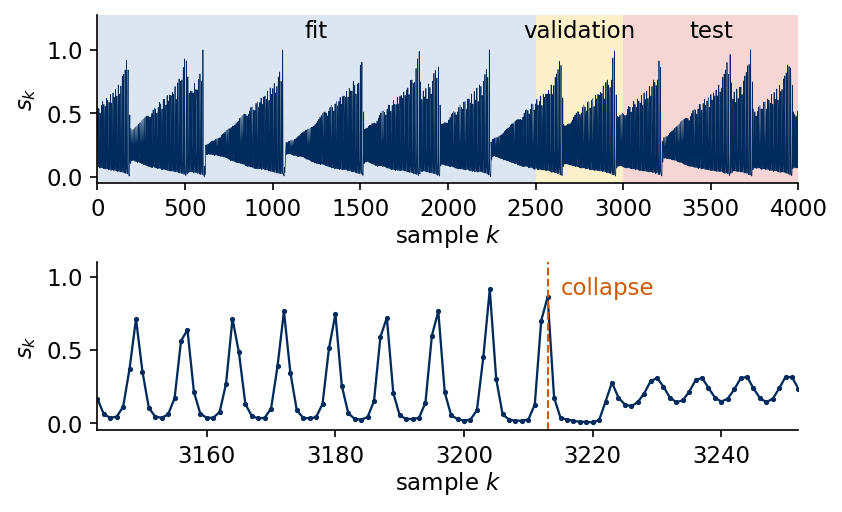

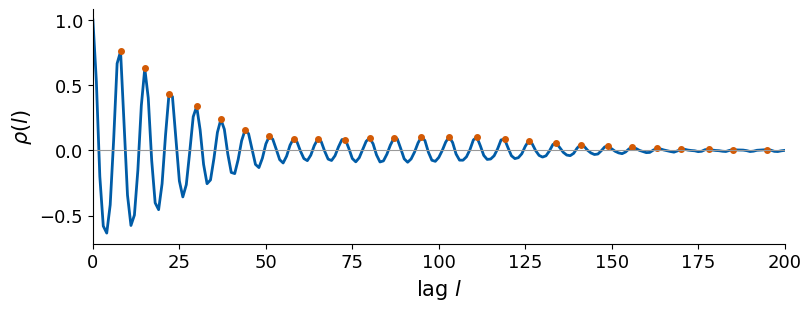

In [3]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 1, figsize=(5.5, 3.3), layout="constrained", gridspec_kw={"height_ratios": [1, 1]})
    ax = axs[0]
    k = np.arange(N_SAMPLES)
    ax.plot(k, s_sf, color=UJNavy, lw=0.35)
    for a, b, c, lab in ((0, N_TRAIN - N_VAL, "#DCE6F2", "fit"), (N_TRAIN - N_VAL, N_TRAIN, "#FBF0C9", "validation"),
                         (N_TRAIN, N_SAMPLES, "#F6D5D5", "test")):
        ax.axvspan(a, b, color=c, zorder=0, lw=0)
        ax.text((a + b) / 2, 1.06, lab, ha="center", va="bottom")
    ax.set_ylim(-0.05, 1.28); ax.set_xlim(0, N_SAMPLES); ax.set_ylabel(r"$s_k$"); ax.set_xlabel("sample $k$", labelpad=1)
    ax = axs[1]
    kz = np.arange(collapse_test[0] - 70, collapse_test[0] + 40)
    ax.plot(kz, s_sf[kz], color=UJNavy, lw=1.1, marker=".", ms=3)
    ax.axvline(collapse_test[0], color=DSOrange, ls="--", lw=1.0)
    ax.text(collapse_test[0] + 2, 1.0, "collapse", color=DSOrange, va="top")
    ax.set_xlim(kz[0], kz[-1]); ax.set_ylim(-0.05, 1.1); ax.set_ylabel(r"$s_k$"); ax.set_xlabel("sample $k$", labelpad=1)
    save(fig, "fig_lab039_santafe"); plt.show()

fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
ax.plot(np.arange(201), acf, color=UJBlue)
ax.plot(acf_peaks, acf[acf_peaks], "o", color=DSOrange, ms=4)
ax.axhline(0, color="0.6", lw=0.8)
ax.set_xlabel(r"lag $l$"); ax.set_ylabel(r"$\rho(l)$"); ax.set_xlim(0, 200)
plt.show()

The upper panel shows the whole record with the fitting, validation and test blocks used below, and the lower panel enlarges the collapse inside the test block. The power spectrum gives a period of 7.43 samples, and the autocorrelation $\rho(l)$ has its maxima at the lags 8, 15, 22 and 30, close to multiples of this period, with heights 0.76, 0.63, 0.43 and 0.34. The decay of these maxima is the loss of phase memory of the chaotic pulsation, a few periods after which the past value at the same phase carries little information about the present. The collapse criterion marks the four sharpest collapses, at the samples 602, 1057, 2236 and 3213. The other drops of the amplitude visible in the record are less abrupt and are not counted. Only one marked collapse, at sample 3213, falls into the test block, so the test scores are dominated by the regular pulsations between collapses.

### Mackey–Glass signals

The second family of test signals comes from the Mackey–Glass delay equation [Mackey and Glass, Science **197**, 287 (1977), [doi:10.1126/science.267326](https://doi.org/10.1126/science.267326)],
$$\dot s(t)=\frac{\beta\,s(t-\tau_{\rm MG})}{1+s(t-\tau_{\rm MG})^{10}}-\gamma\,s(t),\qquad \beta=0.2,\ \gamma=0.1,$$
a model of the production of blood cells in which the delay $\tau_{\rm MG}$ is the maturation time. The state of a delay equation is the whole history on the interval $[t-\tau_{\rm MG},t]$, so the system is infinite-dimensional, and the delay controls the dynamics. We integrate it with the fourth-order Runge–Kutta method (RK4) at step $h=0.1$, interpolate the delayed value linearly at half steps, start from the constant history $s=1.2$, discard the first 3000 steps and keep one sample per time unit. The delay $\tau_{\rm MG}=15$ gives a limit cycle, $\tau_{\rm MG}=25$ weak chaos and $\tau_{\rm MG}=35$ developed chaos. Each signal is rescaled to $[0,1]$ with its first 2500 samples, like the laser.

MG15  N = 4000, test range [0.000, 1.000], largest spectral peak at period 44.8 samples
MG25  N = 4000, test range [-0.035, 1.027], largest spectral peak at period 73.2 samples
MG35  N = 4000, test range [0.004, 1.005], largest spectral peak at period 125.0 samples


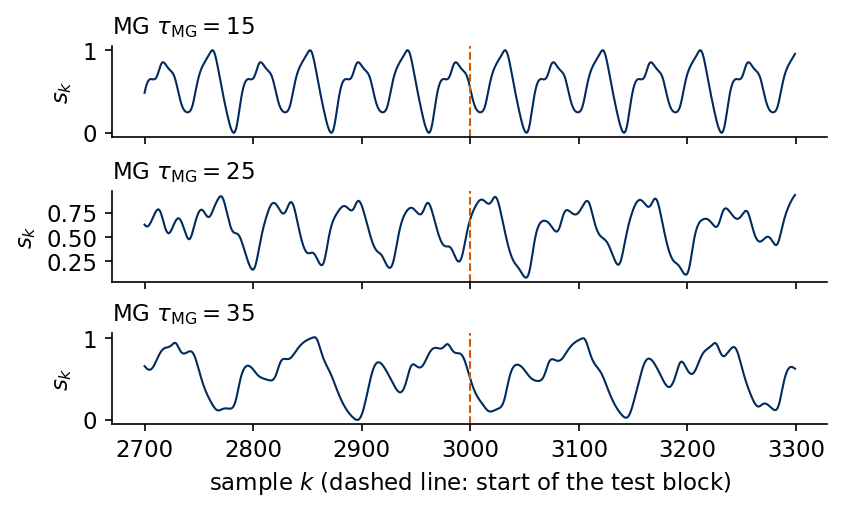

In [4]:
# Mackey-Glass: dx/dt = beta x(t-tau)/(1+x(t-tau)^n) - gamma x, beta=0.2, gamma=0.1, n=10;
# RK4 with h=0.1, the delayed value at half steps by linear interpolation, constant history
# x=1.2 on [-tau, 0], first 3000 fine steps discarded, every 10th point kept (unit sampling).
def mackey_glass(tau, n_samples, h=0.1, x0=1.2, transient=3000, every=10,
                 beta=0.2, gamma=0.1, n=10):
    lag = int(round(tau / h))
    f = lambda x, xd: beta * xd / (1.0 + xd**n) - gamma * x
    def step(buf, _):
        # buf = (x[i-lag], ..., x[i]) : the delay window, length lag+1
        x, xd0, xd1 = buf[-1], buf[0], buf[1]
        xdh = 0.5 * (xd0 + xd1)
        k1 = f(x, xd0); k2 = f(x + 0.5*h*k1, xdh); k3 = f(x + 0.5*h*k2, xdh); k4 = f(x + h*k3, xd1)
        xn = x + h/6.0*(k1 + 2*k2 + 2*k3 + k4)
        return jnp.concatenate([buf[1:], xn[None]]), xn
    n_steps = transient + n_samples * every
    _, xs = jax.lax.scan(step, jnp.full(lag + 1, x0), None, length=n_steps)
    x = np.concatenate([np.full(lag + 1, x0), np.asarray(xs)])
    return x[transient::every][:n_samples]

SIGNALS = ["SantaFe", "MG15", "MG25", "MG35"]
LABEL = {"SantaFe": "Santa Fe laser", "MG15": r"MG $\tau_{\rm MG}=15$", "MG25": r"MG $\tau_{\rm MG}=25$",
         "MG35": r"MG $\tau_{\rm MG}=35$"}
sig = {"SantaFe": s_sf}
for tau_mg in (15, 25, 35):
    sig[f"MG{tau_mg}"] = rescale01(mackey_glass(tau_mg, N_SAMPLES))
for name in SIGNALS[1:]:
    x = sig[name][:N_TRAIN] - sig[name][:N_TRAIN].mean()
    pw = np.abs(np.fft.rfft(x)) ** 2
    print(f"{name:5s} N = {len(sig[name])}, test range [{sig[name][N_TRAIN:].min():.3f}, {sig[name][N_TRAIN:].max():.3f}],"
          f" largest spectral peak at period {N_TRAIN / (np.argmax(pw[1:]) + 1):.1f} samples")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(3, 1, figsize=(5.5, 3.3), sharex=True, layout="constrained")
    for ax, name in zip(axs, SIGNALS[1:]):
        ax.plot(np.arange(N_TRAIN - 300, N_TRAIN + 300), sig[name][N_TRAIN - 300:N_TRAIN + 300], color=UJNavy, lw=1.0)
        ax.axvline(N_TRAIN - 0.5, color=DSOrange, ls="--", lw=1.0)
        ax.set_ylabel(r"$s_k$"); ax.set_title(LABEL[name], loc="left")
    axs[-1].set_xlabel("sample $k$ (dashed line: start of the test block)")
    save(fig, "fig_lab039_mackey_glass"); plt.show()

The three signals change from a strictly periodic oscillation at $\tau_{\rm MG}=15$ to irregular oscillations at $\tau_{\rm MG}=25$ and $35$. The largest spectral peak lies at the periods 44.8, 73.2 and 125.0 samples, so one oscillation of these signals spans tens of samples, against 7.4 samples for the laser. The window of $L=64$ values therefore covers about one oscillation of the chaotic Mackey–Glass signals and more than eight pulses of the laser. The test block of $\tau_{\rm MG}=25$ slightly exceeds the training range, from $-0.035$ to $1.027$.

<hr/>
## 2. Forecasting protocol and scores

The $N=4000$ samples are split in time order. The first 3000 form the training block, and its last 500 samples serve as validation. The final 1000 samples are the test block. The signal is rescaled to $[0,1]$ with the minimum and maximum of the first 2500 samples only, the part of the training block used for fitting, so the validation and test blocks may slightly exceed this interval.

A forecast is made at an origin $k$ from the past and returns all leads $\tau=1,\dots,50$ at once. This is direct forecasting, one output per lead, and the model never sees its own predictions. Every model of this notebook reads at most the window of the last $L=64$ values,
$$\mathbf v_k=(s_{k-L+1},\dots,s_{k-1},s_k)\in\mathbb R^{L},\qquad \mathbf y_k=(s_{k+1},\dots,s_{k+50})\in\mathbb R^{50}.$$
The origins are chosen so that no target crosses a block boundary. Fitting uses the origins $k=63,\dots,2449$ (targets inside the first 2500 samples), validation the origins $k=2499,\dots,2949$ and testing the origins $k=2999,\dots,3949$. A window may reach back into an earlier block, since the inputs are past values known at the time of the forecast.

In [5]:
L_WIN = 64                                                        # window length L
K_FIT = np.arange(L_WIN - 1, N_TRAIN - N_VAL - TAU_MAX)           # origins 63..2449
K_VAL = np.arange(N_TRAIN - N_VAL - 1, N_TRAIN - TAU_MAX)         # origins 2499..2949
K_TEST = np.arange(N_TRAIN - 1, N_SAMPLES - TAU_MAX)              # origins 2999..3949
TAUS = np.arange(1, TAU_MAX + 1)

def windows(s, ks, L=L_WIN):
    # inputs U[i] = (s_{k-L+1}, ..., s_k) and targets Y[i] = (s_{k+1}, ..., s_{k+50}) for k = ks[i]
    U = s[ks[:, None] + np.arange(-L + 1, 1)[None, :]]
    Y = s[ks[:, None] + TAUS[None, :]]
    return U, Y

U_tmp, Y_tmp = windows(s_sf, K_TEST)
assert U_tmp[0, -1] == s_sf[K_TEST[0]] and Y_tmp[0, 0] == s_sf[K_TEST[0] + 1]
assert (K_FIT + TAU_MAX).max() < N_TRAIN - N_VAL and (K_VAL + TAU_MAX).max() < N_TRAIN
assert K_TEST[0] + 1 == N_TRAIN and (K_TEST + TAU_MAX).max() == N_SAMPLES - 1
print(f"origins: fit {len(K_FIT)} ({K_FIT[0]}..{K_FIT[-1]}), validation {len(K_VAL)} ({K_VAL[0]}..{K_VAL[-1]}),"
      f" test {len(K_TEST)} ({K_TEST[0]}..{K_TEST[-1]})")
nums["protocol"] = dict(L=L_WIN, n_fit=len(K_FIT), n_val=len(K_VAL), n_test=len(K_TEST), tau_max=TAU_MAX)

origins: fit 2387 (63..2449), validation 451 (2499..2949), test 951 (2999..3949)


For each lead $\tau$ we compare the predictions $\hat s_{k+\tau}$ with the true values $s_{k+\tau}$ over the $n$ test origins with the Pearson correlation coefficient
$$r(\tau)=\frac{\sum_k(\hat s_{k+\tau}-\bar{\hat s}_\tau)(s_{k+\tau}-\bar s_\tau)}{\sqrt{\sum_k(\hat s_{k+\tau}-\bar{\hat s}_\tau)^2\,\sum_k(s_{k+\tau}-\bar s_\tau)^2}},$$
where the bars are averages over the test origins. It measures how well the shape of the forecast follows the truth, independently of an offset and a scale factor. The forecast capacity $C(\tau)=r(\tau)^2\in[0,1]$ is the fraction of the variance of $s_{k+\tau}$ that a linear rescaling of the forecast explains. Its sum over the 50 leads, the total capacity
$$C_{\rm tot}=\sum_{\tau=1}^{50}C(\tau)\le 50,$$
summarises a whole curve, and the skill horizon $\tau_{1/2}$ is the first lead with $C(\tau)<0.5$. All forecasts of this notebook are scored by $C(\tau)$, $C_{\rm tot}$ and $\tau_{1/2}$.

In [6]:
@jax.jit
def pearson_r(pred, true):
    # pred, true: (n, TAU_MAX); correlation over the n origins, one value per lead
    pc, tc = pred - pred.mean(0), true - true.mean(0)
    return jnp.sum(pc * tc, 0) / jnp.sqrt(jnp.sum(pc ** 2, 0) * jnp.sum(tc ** 2, 0))

def score(pred, true):
    # dictionary with r(tau), C(tau) = r^2, C_tot and the skill horizon tau_1/2
    r = np.asarray(pearson_r(jnp.asarray(pred, jnp.float64), jnp.asarray(true, jnp.float64)))
    C = r ** 2
    below = np.nonzero(C < 0.5)[0]
    return dict(r=r, C=C, Ctot=float(C.sum()), tau_half=int(below[0] + 1) if len(below) else None)

# check the JAX correlation against numpy on random data
rng = np.random.default_rng(0)
a, b = rng.normal(size=(500, TAU_MAX)), rng.normal(size=(500, TAU_MAX))
r_np = np.array([np.corrcoef(a[:, j] + 0.5 * b[:, j], b[:, j])[0, 1] for j in range(TAU_MAX)])
print("max |r_jax - r_numpy| =", np.abs(score(a + 0.5 * b, b)["r"] - r_np).max())

max |r_jax - r_numpy| = 6.106226635438361e-16


<hr/>
## 3. Persistence, AR and NVAR baselines

Persistence repeats the last value, $\hat s_{k+\tau}=s_k$. It needs no fitting and sets the floor that any model must beat. The direct autoregressive (AR) model of order $p$ and the nonlinear vector autoregression (NVAR) are ridge regressions on features of the delay vector $\mathbf d_k=(s_k,s_{k-1},\dots,s_{k-p+1})$,
$$\hat{\mathbf y}_k=W^\top\boldsymbol\phi(\mathbf d_k)+\mathbf b,\qquad \boldsymbol\phi_{\rm AR}=\mathbf d_k,\qquad \boldsymbol\phi_{\rm NVAR}=\big(\mathbf d_k,\ \{s_{k-i}s_{k-j}\}_{0\le i\le j<p}\big),$$
where $W$ has one column per lead and NVAR has $p+p(p+1)/2$ features [Gauthier *et al.*, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)]. Ridge regression minimises $\sum_k\|\hat{\mathbf y}_k-\mathbf y_k\|^2+\beta\|W\|^2$. With centred features $\Phi_c$ and centred targets $Y_c$ the solution is
$$W=(\Phi_c^\top\Phi_c+\beta I)^{-1}\Phi_c^\top Y_c,\qquad \mathbf b=\bar{\mathbf y}-W^\top\bar{\boldsymbol\phi},$$
so the intercept $\mathbf b$ is not penalised. The order $p$ and the ridge strength $\beta$ are chosen by the largest $C_{\rm tot}$ on the validation origins.

In [7]:
def ridge_fit(F, Y, beta):
    # centred ridge regression, F: (n, d) features, Y: (n, m) targets -> W (d, m), b (m,)
    fm, ym = F.mean(0), Y.mean(0)
    Fc, Yc = F - fm, Y - ym
    W = jnp.linalg.solve(Fc.T @ Fc + beta * jnp.eye(F.shape[1]), Fc.T @ Yc)
    return W, ym - fm @ W

def delay_features(s, ks, p):
    # rows (s_k, s_{k-1}, ..., s_{k-p+1})
    return s[ks[:, None] - np.arange(p)[None, :]]

def nvar_features(s, ks, p):
    # delay vector and all quadratic monomials s_{k-i} s_{k-j}, i <= j
    d = delay_features(s, ks, p)
    iu, ju = np.triu_indices(p)
    return np.concatenate([d, d[:, iu] * d[:, ju]], axis=1)

GRID_BETA = (1e-8, 1e-6, 1e-4, 1e-2, 1.0)
GRID_P = {"AR": (4, 8, 16, 24, 32, 48, 64), "NVAR": (2, 4, 8, 12, 16, 24, 32)}
FEATS = {"AR": delay_features, "NVAR": nvar_features}

def ridge_model(s, kind):
    # choose (p, beta) by validation C_tot, return the test predictions and the chosen setting
    _, Yf = windows(s, K_FIT); _, Yv = windows(s, K_VAL); _, Yt = windows(s, K_TEST)
    best = (-1.0, None, None)
    for p in GRID_P[kind]:
        Ff, Fv = FEATS[kind](s, K_FIT, p), FEATS[kind](s, K_VAL, p)
        for beta in GRID_BETA:
            W, b = ridge_fit(Ff, Yf, beta)
            ctot = score(Fv @ W + b, Yv)["Ctot"]
            if ctot > best[0]:
                best = (ctot, p, beta)
    _, p, beta = best
    Ff, Ft = FEATS[kind](s, K_FIT, p), FEATS[kind](s, K_TEST, p)
    W, b = ridge_fit(Ff, Yf, beta)
    return dict(pred=np.asarray(Ft @ W + b), p=p, beta=beta, n_feat=Ff.shape[1], **score(Ft @ W + b, Yt))

res = {name: {} for name in SIGNALS}       # res[signal][model] = scores and test predictions
R = res["SantaFe"]                         # the Santa Fe results, used most often
for name in SIGNALS:
    U_t, Y_t = windows(sig[name], K_TEST)
    res[name]["persistence"] = dict(pred=np.repeat(U_t[:, -1:], TAU_MAX, 1), **score(np.repeat(U_t[:, -1:], TAU_MAX, 1), Y_t))
    for kind in ("AR", "NVAR"):
        res[name][kind] = ridge_model(sig[name], kind)
    for m in ("persistence", "AR", "NVAR"):
        r_ = res[name][m]
        extra = f" (p = {r_['p']}, beta = {r_['beta']:.0e}, {r_['n_feat']} features)" if m != "persistence" else ""
        print(f"{name:8s} {m:12s} C_tot = {r_['Ctot']:5.1f}, tau_1/2 = {str(r_['tau_half'] or '>50'):>3s}" + extra)
U_test, Y_test = windows(s_sf, K_TEST)

SantaFe  persistence  C_tot =   5.5, tau_1/2 =   1
SantaFe  AR           C_tot =  16.5, tau_1/2 =  16 (p = 64, beta = 1e+00, 64 features)
SantaFe  NVAR         C_tot =  34.7, tau_1/2 =  42 (p = 32, beta = 1e-02, 560 features)


MG15     persistence  C_tot =  19.5, tau_1/2 =   6
MG15     AR           C_tot =  49.8, tau_1/2 = >50 (p = 64, beta = 1e-08, 64 features)
MG15     NVAR         C_tot =  50.0, tau_1/2 = >50 (p = 32, beta = 1e-08, 560 features)


MG25     persistence  C_tot =  13.3, tau_1/2 =   8
MG25     AR           C_tot =  33.1, tau_1/2 =  42 (p = 64, beta = 1e-08, 64 features)
MG25     NVAR         C_tot =  45.5, tau_1/2 = >50 (p = 32, beta = 1e-08, 560 features)


MG35     persistence  C_tot =  11.8, tau_1/2 =  10
MG35     AR           C_tot =  38.0, tau_1/2 = >50 (p = 64, beta = 1e-08, 64 features)
MG35     NVAR         C_tot =  48.6, tau_1/2 = >50 (p = 32, beta = 1e-08, 560 features)


On the laser, persistence reaches $C_{\rm tot}=5.5$ and drops below $C=0.5$ already at $\tau=1$, since one step is a seventh of a pulsation period. The AR model with $p=64$ delays reaches $C_{\rm tot}=16.5$ and $\tau_{1/2}=16$, and NVAR with $p=32$ delays and 560 features reaches $34.7$ and $\tau_{1/2}=42$. The quadratic features double the capacity of the linear model, which shows how nonlinear the map from the past window to the future of the laser is. On the Mackey–Glass limit cycle ($\tau_{\rm MG}=15$) the linear AR model is already close to the maximum, with $C_{\rm tot}=49.8$ against $50.0$ for NVAR. In the chaotic regimes AR reaches 33.1 and 38.0 and NVAR 45.5 and 48.6 at $\tau_{\rm MG}=25$ and $35$.

Ridge regression with scikit-learn gives the same predictions, since `Ridge` with `fit_intercept=True` also centres the data and leaves the intercept unpenalised.

In [8]:
for kind in ("AR", "NVAR"):
    p, beta = R[kind]["p"], R[kind]["beta"]
    _, Yf = windows(s_sf, K_FIT)
    sk = SkRidge(alpha=beta, fit_intercept=True).fit(FEATS[kind](s_sf, K_FIT, p), Yf)
    diff = np.abs(sk.predict(FEATS[kind](s_sf, K_TEST, p)) - R[kind]["pred"]).max()
    print(f"{kind:4s} (p = {p}): max |prediction JAX - prediction scikit-learn| = {diff:.2e}")

AR   (p = 64): max |prediction JAX - prediction scikit-learn| = 1.44e-15
NVAR (p = 32): max |prediction JAX - prediction scikit-learn| = 2.06e-12


The JAX and scikit-learn predictions agree to $10^{-15}$ for AR and to $2\times10^{-12}$ for NVAR, whose 560 features make the linear system less well conditioned.

<hr/>
## 4. Simple recurrent network

A recurrent neural network (RNN) reads the window one value at a time and keeps what it has seen in a hidden state $\mathbf h_k\in\mathbb R^{n_h}$ [Elman, Cogn. Sci. **14**, 179 (1990), [doi:10.1207/s15516709cog1402_1](https://doi.org/10.1207/s15516709cog1402_1)],
$$\mathbf h_k=\tanh\!\big(W_h\mathbf h_{k-1}+W_x s_k+\mathbf b\big),\qquad \hat{\mathbf y}_k=W_y\mathbf h_k+\mathbf b_y ,$$
with $W_h\in\mathbb R^{n_h\times n_h}$, $W_x\in\mathbb R^{n_h\times1}$, $\mathbf b\in\mathbb R^{n_h}$ and the readout $W_y\in\mathbb R^{50\times n_h}$, $\mathbf b_y\in\mathbb R^{50}$. Every forecast starts from $\mathbf h=0$ at the beginning of the window, the $L=64$ values of $\mathbf v_k$ are fed in order, and the 50 leads are read linearly from the last state. Output $\tau$ is the forecast $\hat s_{k+\tau}$, and no prediction is fed back.

Training needs the derivative of the loss with respect to the weights, and the chain rule through the unrolled sequence, called backpropagation through time (BPTT), carries it from the last state back to earlier ones. A change of the state $\mathbf h_j$ reaches $\mathbf h_k$ through the product of step Jacobians
$$\frac{\partial\mathbf h_k}{\partial\mathbf h_j}=\prod_{i=j+1}^{k}D_iW_h,\qquad D_i=\mathrm{diag}\big(1-\mathbf h_i^2\big),$$
where $D_i$ holds the derivatives $\tanh'=1-\tanh^2\in(0,1]$. An input $m$ steps in the past contributes to the gradient through $m$ such factors. When the factors shrink vectors, the product decays exponentially with $m$, and the network receives almost no training signal from distant inputs. This is the vanishing gradient problem [Bengio, Simard and Frasconi, IEEE Trans. Neural Netw. **5**, 157 (1994), [doi:10.1109/72.279181](https://doi.org/10.1109/72.279181)]. When they stretch vectors, the gradient explodes [Pascanu, Mikolov and Bengio, ICML (2013), [arXiv:1211.5063](https://arxiv.org/abs/1211.5063)].

<hr/>
## 5. The LSTM cell

The long short-term memory (LSTM) network [Hochreiter and Schmidhuber, Neural Comput. **9**, 1735 (1997), [doi:10.1162/neco.1997.](https://doi.org/10.1162/neco.1997.)] was designed against the vanishing gradient. Next to the hidden state $\mathbf h_k\in\mathbb R^{n_h}$ it carries a cell state $\mathbf c_k\in\mathbb R^{n_h}$, and three gates with values in $(0,1)$ decide what is kept, written and shown. Every gate reads the previous hidden state together with the new input, stacked into one vector,
$$[\mathbf h_{k-1},s_k]=\big(h_{k-1,1},\dots,h_{k-1,n_h},\,s_k\big)^\top\in\mathbb R^{n_h+1}.$$
With the logistic sigmoid $\sigma(a)=1/(1+e^{-a})$ and the elementwise (Hadamard) product $\odot$, $(\mathbf a\odot\mathbf b)_j=a_jb_j$, one step of the cell is
$$
\begin{aligned}
\mathbf f_k&=\sigma\big(W_f[\mathbf h_{k-1},s_k]+\mathbf b_f\big) &&\text{forget gate}\\
\mathbf i_k&=\sigma\big(W_i[\mathbf h_{k-1},s_k]+\mathbf b_i\big) &&\text{input gate}\\
\mathbf g_k&=\tanh\big(W_g[\mathbf h_{k-1},s_k]+\mathbf b_g\big) &&\text{candidate}\\
\mathbf o_k&=\sigma\big(W_o[\mathbf h_{k-1},s_k]+\mathbf b_o\big) &&\text{output gate}\\
\mathbf c_k&=\mathbf f_k\odot\mathbf c_{k-1}+\mathbf i_k\odot\mathbf g_k\\
\mathbf h_k&=\mathbf o_k\odot\tanh(\mathbf c_k),
\end{aligned}
$$
with $W_f,W_i,W_g,W_o\in\mathbb R^{n_h\times(n_h+1)}$ and biases $\mathbf b_f,\mathbf b_i,\mathbf b_g,\mathbf b_o\in\mathbb R^{n_h}$. The sigmoid and tanh act on each component. The forget gate $\mathbf f_k$ sets the fraction of each component of $\mathbf c_{k-1}$ that survives, the input gate $\mathbf i_k$ the fraction of the candidate $\mathbf g_k\in(-1,1)^{n_h}$ that is written, and the output gate $\mathbf o_k$ the fraction of $\tanh(\mathbf c_k)$ that appears in $\mathbf h_k$. The forecaster is the same as for the RNN. The cell starts from $\mathbf c=\mathbf h=0$, reads the window, and the readout $\hat{\mathbf y}_k=W_y\mathbf h_k+\mathbf b_y$ acts on the last hidden state.

The drawing shows one step. The line on top is the cell state, and the four blocks below are the gates and the candidate, each fed by $[\mathbf h_{k-1},s_k]$.

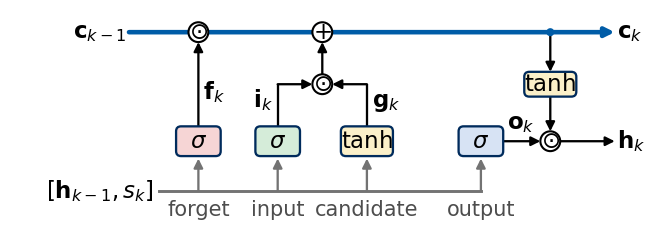

In [9]:
def box(ax, xy, text, w=0.9, h=0.6, fc="#DCE6F2", ec=UJNavy, fs=11, lw=1.1):
    # rounded box centred at xy
    ax.add_patch(FancyBboxPatch((xy[0] - w / 2, xy[1] - h / 2), w, h, boxstyle="round,pad=0.0,rounding_size=0.1",
                                fc=fc, ec=ec, lw=lw, zorder=3))
    ax.text(xy[0], xy[1], text, ha="center", va="center", fontsize=fs, zorder=4)

def op(ax, xy, sym, r=0.2, fs=11):
    # circle with an elementwise operation symbol
    ax.add_patch(Circle(xy, r, fc="white", ec="k", lw=1.0, zorder=3))
    ax.text(xy[0], xy[1], sym, ha="center", va="center", fontsize=fs, zorder=4)

def arrow(ax, pts, color="k", lw=1.1, ls="-", head=True):
    # polyline through the points pts; arrow head on the last segment
    pts = np.asarray(pts, float)
    for p0, p1 in zip(pts[:-2], pts[1:-1]):
        ax.plot([p0[0], p1[0]], [p0[1], p1[1]], color=color, lw=lw, ls=ls, zorder=2, solid_capstyle="butt")
    ax.annotate("", xy=pts[-1], xytext=pts[-2], zorder=2,
                arrowprops=dict(arrowstyle="-|>" if head else "-", color=color, lw=lw, ls=ls,
                                shrinkA=0, shrinkB=0, mutation_scale=9))

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.85))
    Y_TOP, Y_G, Y_BUS = 3.8, 1.6, 0.6
    GX = {"f": 2.4, "i": 4.0, "g": 5.8, "o": 8.1}
    # cell-state line on top: c_{k-1} -> c_k, touched only by elementwise operations
    arrow(ax, [(1.0, Y_TOP), (10.8, Y_TOP)], color=UJBlue, lw=2.2)
    ax.text(0.95, Y_TOP, r"$\mathbf{c}_{k-1}$", ha="right", va="center")
    ax.text(10.85, Y_TOP, r"$\mathbf{c}_k$", ha="left", va="center")
    # input bus [h_{k-1}, s_k] below the gates, one branch into every block
    ax.plot([1.6, GX["o"]], [Y_BUS, Y_BUS], color="0.45", lw=1.4, zorder=2)
    ax.text(1.5, Y_BUS, r"$[\mathbf{h}_{k-1},s_k]$", ha="right", va="center")
    for gx in GX.values():
        arrow(ax, [(gx, Y_BUS), (gx, Y_BUS + 0.65)], color="0.45")
    for key, fc, txt in (("f", "#F6D5D5", r"$\sigma$"), ("i", "#D5ECD9", r"$\sigma$"), ("g", "#FBF0C9", r"$\tanh$"),
                         ("o", "#D7E3F4", r"$\sigma$")):
        box(ax, (GX[key], Y_G), txt, w=1.05 if key == "g" else 0.9, h=0.6, fc=fc)
    op(ax, (GX["f"], Y_TOP), r"$\odot$")                  # forget: f_k * c_{k-1}
    op(ax, (4.9, Y_TOP), r"$+$")                          # add the written candidate
    op(ax, (4.9, 2.75), r"$\odot$")                       # i_k * g_k
    arrow(ax, [(GX["f"], Y_G + 0.3), (GX["f"], Y_TOP - 0.2)]); ax.text(GX["f"] + 0.1, 2.45, r"$\mathbf{f}_k$", ha="left")
    arrow(ax, [(GX["i"], Y_G + 0.3), (GX["i"], 2.75), (4.7, 2.75)]); ax.text(GX["i"] - 0.1, 2.3, r"$\mathbf{i}_k$", ha="right")
    arrow(ax, [(GX["g"], Y_G + 0.3), (GX["g"], 2.75), (5.1, 2.75)]); ax.text(GX["g"] + 0.1, 2.3, r"$\mathbf{g}_k$", ha="left")
    arrow(ax, [(4.9, 2.95), (4.9, Y_TOP - 0.2)])
    # output branch: o_k * tanh(c_k) -> h_k
    ax.add_patch(Circle((9.5, Y_TOP), 0.06, color=UJBlue, zorder=4))
    box(ax, (9.5, 2.75), r"$\tanh$", w=1.05, h=0.5, fc="#FBF0C9")
    arrow(ax, [(9.5, Y_TOP), (9.5, 3.0)])
    op(ax, (9.5, Y_G), r"$\odot$")
    arrow(ax, [(9.5, 2.5), (9.5, Y_G + 0.2)])
    arrow(ax, [(GX["o"] + 0.45, Y_G), (9.3, Y_G)]); ax.text(8.9, Y_G + 0.12, r"$\mathbf{o}_k$", ha="center", va="bottom")
    arrow(ax, [(9.7, Y_G), (10.8, Y_G)]); ax.text(10.85, Y_G, r"$\mathbf{h}_k$", ha="left", va="center")
    for key, name in (("f", "forget"), ("i", "input"), ("g", "candidate"), ("o", "output")):
        ax.text(GX[key], Y_BUS - 0.18, name, ha="center", va="top", color="0.3", fontsize=10)
    ax.set_xlim(-1.3, 11.6); ax.set_ylim(-0.05, 4.15); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_lab039_lstm_cell"); plt.show()

The drawing follows the equations from left to right. The forget gate multiplies the old cell state, the product $\mathbf i_k\odot\mathbf g_k$ is added to it, and the output branch on the right squashes the new cell state with tanh and multiplies it by $\mathbf o_k$. The cell-state line on top passes only through the elementwise operations $\odot$ and $+$.

### Gradient along the cell state

The cell state is updated by an elementwise product and a sum, with no weight matrix and no squashing function between $\mathbf c_{k-1}$ and $\mathbf c_k$. Holding the gates fixed, the derivative along this direct path is diagonal,
$$\left.\frac{\partial\mathbf c_k}{\partial\mathbf c_{k-1}}\right|_{\rm cell}=\mathrm{diag}(\mathbf f_k),\qquad \left.\frac{\partial\mathbf c_k}{\partial\mathbf c_{j}}\right|_{\rm cell}=\prod_{i=j+1}^{k}\mathrm{diag}(\mathbf f_i).$$
The full Jacobian contains further terms, because $\mathbf c_{k-1}$ also enters the gates through $\mathbf h_{k-1}=\mathbf o_{k-1}\odot\tanh(\mathbf c_{k-1})$, and these terms pass through the weight matrices like the RNN product. The direct term involves no weight matrix, and each component $j$ decays by the factor $f_{i,j}$ per step, so the network can keep a gradient alive over many steps by holding its forget values close to 1. In the original LSTM the cell had a fixed self-connection of weight 1, the constant error carousel, through which errors flow back without decay. The forget gate, added by Gers, Schmidhuber and Cummins [Neural Comput. **12**, 2451 (2000), [doi:10.1162/089976600300015015](https://doi.org/10.1162/089976600300015015)], makes this factor learnable.

A unit with a constant forget value $f$ keeps the fraction $f^m=e^{-m/\tau_{\rm mem}}$ of its content after $m$ steps, which defines the memory time
$$\tau_{\rm mem}=-\frac{1}{\ln f}.$$
For $f=0.9$ this is 9.5 steps and for $f=0.99$ it is 99.5 steps. Gers *et al.* recommend a positive initial forget bias, so that the cell starts by keeping information. We initialise $\mathbf b_f=1$, which gives $f=\sigma(1)\approx0.73$ and $\tau_{\rm mem}\approx3.2$ steps for an input of zero, and let the training change it.

### Parameter count

Each of the four blocks has a matrix of $n_h(n_h+1)$ entries acting on $[\mathbf h_{k-1},s_k]$ and a bias of $n_h$ entries, and the RNN has one such block. With the readout to 50 leads,
$$P_{\rm LSTM}=4\big(n_h(n_h+1)+n_h\big)+50(n_h+1),\qquad P_{\rm RNN}=n_h(n_h+1)+n_h+50(n_h+1).$$
For $n_h=32$ this gives 4 $\times$ 1088 + 1650 = 6002 and 1088 + 1650 = 2738 parameters, which we check against the modules below.

<hr/>
## 6. LSTM implementation in JAX

A cell is an `nnx.Module` with one method, `cell(carry, s_k) -> (carry, h_k)`, the signature of the library cells. The carry is $\mathbf h$ for the RNN and the pair $(\mathbf c,\mathbf h)$ for the LSTM. A cell acts on a batch, so $s_k$ has shape $(B,1)$ and $\mathbf h$ has shape $(B,n_h)$. Our LSTM cell stores the four matrices $W_i,W_f,W_g,W_o$ as one `nnx.Linear` layer from $n_h+1$ to $4n_h$ outputs acting on the concatenation $[\mathbf h_{k-1},s_k]$, and splits the result into the four pre-activations. The module `Recurrent` runs any cell over the window with `jax.lax.scan`, which compiles the loop over the $L$ steps once, and applies the linear readout to the last hidden state. The window has shape $(B,L,1)$ and scan iterates over the leading axis, so we swap the batch and time axes before the loop.

The input matrices use the LeCun normal initialisation (variance $1/n_{\rm in}$), the recurrent matrix of the RNN a random orthogonal matrix, whose singular values all equal 1, so that $W_h$ alone neither shrinks nor grows the Jacobian product at the start, and the LSTM gets $\mathbf b_f=1$ with all other biases zero.

In [10]:
orthogonal = nnx.initializers.orthogonal()

class RNNCell(nnx.Module):
    # h_k = tanh(W_x s_k + b + W_h h_{k-1})
    def __init__(self, n_x, n_h, *, rngs):
        self.n_h = n_h
        self.Wx = nnx.Linear(n_x, n_h, rngs=rngs)                                   # W_x and b
        self.Wh = nnx.Linear(n_h, n_h, use_bias=False, kernel_init=orthogonal, rngs=rngs)
    def init_carry(self, B, dtype):
        return jnp.zeros((B, self.n_h), dtype)
    def __call__(self, h, s):
        h = jnp.tanh(self.Wx(s) + self.Wh(h))
        return h, h

class LSTMCell(nnx.Module):
    # one matrix on the concatenation [h_{k-1}, s_k] for the four blocks in the order (i, f, g, o)
    def __init__(self, n_x, n_h, *, rngs, forget_bias=1.0):
        self.n_h = n_h
        self.W = nnx.Linear(n_h + n_x, 4 * n_h, rngs=rngs)
        self.W.bias[...] = self.W.bias[...].at[n_h:2 * n_h].set(forget_bias)      # b_f = 1 (Gers et al. 2000)
    def init_carry(self, B, dtype):
        return (jnp.zeros((B, self.n_h), dtype), jnp.zeros((B, self.n_h), dtype))
    def gates(self, carry, s):
        c, h = carry
        a_i, a_f, a_g, a_o = jnp.split(self.W(jnp.concatenate([h, s], axis=-1)), 4, axis=-1)
        return jax.nn.sigmoid(a_i), jax.nn.sigmoid(a_f), jnp.tanh(a_g), jax.nn.sigmoid(a_o)
    def __call__(self, carry, s):
        c, h = carry
        i, f, g, o = self.gates(carry, s)
        c = f * c + i * g                               # cell state: elementwise only
        h = o * jnp.tanh(c)
        return (c, h), h

class Recurrent(nnx.Module):
    # any cell run over the window, linear readout of the last hidden state to the outputs
    def __init__(self, cell, n_h, n_out, *, rngs):
        self.cell = cell
        self.head = nnx.Linear(n_h, n_out, rngs=rngs)    # W_y, b_y
    def hidden_states(self, V):
        # V: (B, L, 1) -> all hidden states (L, B, n_h)
        carry = self.cell.init_carry(V.shape[0], V.dtype)
        _, hs = jax.lax.scan(lambda c, s: self.cell(c, s), carry, jnp.swapaxes(V, 0, 1))
        return hs
    def __call__(self, V):
        return self.head(self.hidden_states(V)[-1])

N_H = 32
CELLS = {"RNN": RNNCell, "LSTM": LSTMCell}

def make_model(kind, seed, n_h=N_H, n_out=TAU_MAX):
    rngs = nnx.Rngs(seed)
    return Recurrent(CELLS[kind](1, n_h, rngs=rngs), n_h, n_out, rngs=rngs)

def n_params(model):
    return int(sum(x.size for x in jax.tree.leaves(nnx.state(model, nnx.Param))))

for kind in ("RNN", "LSTM"):
    m = make_model(kind, 0)
    P_formula = (4 if kind == "LSTM" else 1) * (N_H * (N_H + 1) + N_H) + TAU_MAX * (N_H + 1)
    assert n_params(m) == P_formula
    print(f"{kind:5s} parameters: formula {P_formula}, module {n_params(m)}")
nums["param_counts"] = {k: n_params(make_model(k, 0)) for k in ("RNN", "LSTM")}

RNN   parameters: formula 2738, module 2738


LSTM  parameters: formula 6002, module 6002


Both formulas agree with the parameter counts of the modules, 2738 for the RNN forecaster and 6002 for the LSTM forecaster with $n_h=32$. The LSTM has 4352 parameters in the cell and 1650 in the readout.

### Check against the library cell

Flax provides `nnx.LSTMCell` with the same equations and a different storage of the weights. It keeps eight separate matrices, `ii, if_, ig, io` acting on the input and `hi, hf, hg, ho` acting on the hidden state, with the biases on the hidden side. `nnx.OptimizedLSTMCell` computes the same step with two matrices that hold the four blocks side by side, `dense_i` for the input and `dense_h` with the bias for the hidden state, which saves separate matrix products. We copy the library weights into our single matrix, the hidden-state rows first and the input row last as in $[\mathbf h_{k-1},s_k]$, and run the cells on the same random sequence of length 64 and batch size 8. The same check is made for the simple RNN cell against `nnx.SimpleCell`.

In [11]:
def run_cell(cell, carry, S):
    # S: (L, B, n_x) -> hidden states (L, B, n_h)
    return jax.lax.scan(lambda c, s: cell(c, s), carry, S)[1]

B_chk, L_chk = 8, 64
S_chk = jax.random.uniform(jax.random.key(3), (L_chk, B_chk, 1), jnp.float32)
h0 = jnp.zeros((B_chk, N_H), jnp.float32)

lib = nnx.LSTMCell(1, N_H, rngs=nnx.Rngs(1)); own = LSTMCell(1, N_H, rngs=nnx.Rngs(2))
K_h = jnp.concatenate([getattr(lib, a).kernel[...] for a in ("hi", "hf", "hg", "ho")], axis=1)   # (n_h, 4 n_h)
K_i = jnp.concatenate([getattr(lib, a).kernel[...] for a in ("ii", "if_", "ig", "io")], axis=1)  # (1, 4 n_h)
own.W.kernel[...] = jnp.concatenate([K_h, K_i], axis=0)                                         # rows: [h, s]
own.W.bias[...] = jnp.concatenate([getattr(lib, a).bias[...] for a in ("hi", "hf", "hg", "ho")])
print("LSTM max |h_own - h_flax LSTMCell| =", float(jnp.abs(run_cell(own, (h0, h0), S_chk) - run_cell(lib, (h0, h0), S_chk)).max()))

# nnx.OptimizedLSTMCell keeps the four blocks side by side, dense_i (input, no bias) and dense_h (hidden, with bias)
lib_opt = nnx.OptimizedLSTMCell(1, N_H, rngs=nnx.Rngs(4)); own_opt = LSTMCell(1, N_H, rngs=nnx.Rngs(2))
own_opt.W.kernel[...] = jnp.concatenate([lib_opt.dense_h.kernel[...], lib_opt.dense_i.kernel[...]], axis=0)
own_opt.W.bias[...] = lib_opt.dense_h.bias[...]
print("LSTM max |h_own - h_flax OptimizedLSTMCell| =",
      float(jnp.abs(run_cell(own_opt, (h0, h0), S_chk) - run_cell(lib_opt, (h0, h0), S_chk)).max()))

lib = nnx.SimpleCell(1, N_H, rngs=nnx.Rngs(1)); own = RNNCell(1, N_H, rngs=nnx.Rngs(2))
own.Wx.kernel[...] = lib.dense_i.kernel[...]; own.Wx.bias[...] = lib.dense_i.bias[...]
own.Wh.kernel[...] = lib.dense_h.kernel[...]
print("RNN  max |h_own - h_flax| =", float(jnp.abs(run_cell(own, h0, S_chk) - run_cell(lib, h0, S_chk)).max()))

LSTM max |h_own - h_flax LSTMCell| = 0.0


LSTM max |h_own - h_flax OptimizedLSTMCell| = 0.0
RNN  max |h_own - h_flax| = 0.0


Our cell and both library cells give identical hidden states over 64 steps, with a largest difference of zero in float32, and the same holds for the RNN cell. The four equations of the cell are thus implemented with the gate order $(i,f,g,o)$ and the bias placement of the library.

Automatic differentiation confirms the diagonal derivative along the cell state. For one step of an untrained cell we differentiate $\mathbf c_k$ with respect to $\mathbf c_{k-1}$ while $\mathbf h_{k-1}$ and $s_k$ are held fixed, which is the derivative with the gates fixed, and compare it with $\mathrm{diag}(\mathbf f_k)$.

In [12]:
cell = make_model("LSTM", 0).cell
key_c, key_h = jax.random.split(jax.random.key(5))
c_prev = jax.random.normal(key_c, (1, N_H)); h_prev = 0.5 * jax.random.normal(key_h, (1, N_H)); s_k = jnp.array([[0.4]])
J_cc = jax.jacfwd(lambda c: cell((c, h_prev), s_k)[0][0][0])(c_prev)[:, 0, :]   # dc_k/dc_{k-1}, h_{k-1} fixed
f_k = cell.gates((c_prev, h_prev), s_k)[1][0]
print("max |dc_k/dc_{k-1} - diag(f_k)| =", float(jnp.abs(J_cc - jnp.diag(f_k)).max()),
      f"| forget values in [{float(f_k.min()):.2f}, {float(f_k.max()):.2f}]")

max |dc_k/dc_{k-1} - diag(f_k)| = 0.0 | forget values in [0.57, 0.93]


The derivative computed by automatic differentiation equals $\mathrm{diag}(\mathbf f_k)$ to the last digit, with forget values between 0.57 and 0.93 for this random state. With the forget bias of 1 the untrained gates already lie well above $1/2$.

`nnx.tabulate` lists the submodules of the LSTM forecaster with the shapes of their outputs and parameters, here for a batch of two windows. The hidden states have the shape $(L,B,n_h)=(64,2,32)$, the single matrix of the cell has $33\times128$ entries plus 128 biases, and the readout maps the 32 hidden values to the 50 leads.

In [13]:
V_two = jnp.asarray(windows(s_sf, K_TEST[:2])[0][..., None], jnp.float32)
print(nnx.tabulate(make_model("LSTM", 0), V_two, depth=2, console_kwargs={"width": 120}))

                                       Recurrent Summary                                        
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ path            ┃ type      ┃ inputs            ┃ outputs          ┃ Param                   ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ hidden_states   │ Recurrent │ float32[2,64,1]   │ float32[64,2,32] │ 6,002 (24.0 KB)         │
├─────────────────┼───────────┼───────────────────┼──────────────────┼─────────────────────────┤
│ cell/init_carry │ LSTMCell  │ - 2               │ - float32[2,32]  │ 4,352 (17.4 KB)         │
│                 │           │ - dtype(float32)  │ - float32[2,32]  │                         │
├─────────────────┼───────────┼───────────────────┼──────────────────┼─────────────────────────┤
│ cell/gates      │ LSTMCell  │ - - float32[2,32] │ - float32[2,32]  │ 4,352 (17.4 KB)         │
│                 │           │   - float32[2,32] │ - float32[2,32]  │                         │
│                 │           │ - float32[2,1]    │ - float32[2,32]  │                         │
│                 │           │                   │ - float32[2,32]  │                         │
├─────────────────┼───────────┼───────────────────┼──────────────────┼─────────────────────────┤
│ cell/W          │ Linear    │ float32[2,33]     │ float32[2,128]   │ bias: float32[128]      │
│                 │           │                   │                  │ kernel: float32[33,128] │
│                 │           │                   │                  │                         │
│                 │           │                   │                  │ 4,352 (17.4 KB)         │
├─────────────────┼───────────┼───────────────────┼──────────────────┼─────────────────────────┤
│ head            │ Linear    │ float32[2,32]     │ float32[2,50]    │ bias: float32[50]       │
│                 │           │                   │                  │ kernel: float32[32,50]  │
│                 │           │                   │                  │                         │
│                 │           │                   │                  │ 1,650 (6.6 KB)          │
├─────────────────┼───────────┼───────────────────┼──────────────────┼─────────────────────────┤
│                 │           │                   │            Total │ 6,002 (24.0 KB)         │
└─────────────────┴───────────┴───────────────────┴──────────────────┴─────────────────────────┘
                                                                                                
                               Total Parameters: 6,002 (24.0 KB)                                

<hr/>
## 7. Training

The training set consists of the windows $(\mathbf v_k,\mathbf y_k)$ for the fitting origins, an array of shape $(n_{\rm fit},L,1)$ of inputs and $(n_{\rm fit},50)$ of targets. Neighbouring windows overlap in $L-1$ values, so we shuffle them at every epoch and cut them into minibatches of $B=128$ windows. The loss is the mean-square error (MSE) over the minibatch and all 50 leads,
$$\mathcal L=\frac{1}{50\,B}\sum_{k\in\text{batch}}\sum_{\tau=1}^{50}\big(\hat s_{k+\tau}-s_{k+\tau}\big)^2 ,$$
so every lead is trained with the same weight. The Adam optimiser [Kingma and Ba, ICLR (2015), [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)] with learning rate $5\times10^{-3}$ updates the weights. Before every update the gradient is rescaled when its Euclidean norm over all parameters exceeds 1, a gradient clipping that protects against rare very large gradients [Pascanu *et al.* (2013)]. After every epoch we compute the loss on the validation windows, keep the parameters with the lowest validation loss and stop when it has not improved for 20 epochs, at most after 250 epochs. This early stopping is the only protection against overfitting, and the test block is never used during training.

`nnx.split` separates a model into its structure (`graphdef`) and its parameters, which makes the loss a pure function of the parameters. `jax.value_and_grad` returns loss and gradient, `optax.chain(clip_by_global_norm, adam)` turns the gradient into an update, and one `jax.lax.scan` over the minibatches forms an epoch that `jax.jit` compiles once.

In [14]:
BATCH, LR, CLIP, MAX_EPOCHS, PATIENCE = 128, 5e-3, 1.0, 250, 20

def fit_network(model, data, seed=0, epochs=MAX_EPOCHS, patience=PATIENCE, verbose=True):
    # data = (U_fit, Y_fit, U_val, Y_val), inputs of shape (n, L, 1), float32
    Uf, Yf, Uv, Yv = data
    graphdef, params, rest = nnx.split(model, nnx.Param, ...)
    tx = optax.chain(optax.clip_by_global_norm(CLIP), optax.adam(LR))
    opt_state = tx.init(params)
    n = Uf.shape[0]; n_batches = n // BATCH

    def loss_fn(p, U, Y):
        return jnp.mean((nnx.merge(graphdef, p, rest)(U) - Y) ** 2)

    @jax.jit
    def epoch(p, opt_state, key):
        idx = jax.random.permutation(key, n)[: n_batches * BATCH].reshape(n_batches, BATCH)
        def step(carry, ib):
            p, opt_state = carry
            loss, g = jax.value_and_grad(loss_fn)(p, Uf[ib], Yf[ib])
            gnorm = optax.global_norm(g)                  # norm before clipping
            upd, opt_state = tx.update(g, opt_state, p)
            return (optax.apply_updates(p, upd), opt_state), (loss, gnorm)
        (p, opt_state), (losses, gnorms) = jax.lax.scan(step, (p, opt_state), idx)
        return p, opt_state, losses.mean(), gnorms, loss_fn(p, Uv, Yv)

    key = jax.random.key(seed)
    hist = dict(train=[], val=[], gnorm=[], clipped=[])
    best_val, best_params, best_ep, t0 = np.inf, params, 0, time.time()
    for ep in range(epochs):
        key, sub = jax.random.split(key)
        params, opt_state, l_tr, gn, l_va = epoch(params, opt_state, sub)
        gn = np.asarray(gn)
        hist["train"].append(float(l_tr)); hist["val"].append(float(l_va))
        hist["gnorm"].append(float(np.median(gn))); hist["clipped"].append(float(np.mean(gn > CLIP)))
        if float(l_va) < best_val:
            best_val, best_params, best_ep = float(l_va), params, ep
        elif ep - best_ep >= patience:
            break
    hist = {k: np.array(v) for k, v in hist.items()}
    hist.update(best_epoch=best_ep + 1, epochs_run=ep + 1, time=time.time() - t0, best_val=best_val)
    if verbose:
        print(f"    {ep + 1:3d} epochs, best validation loss {best_val:.2e} at epoch {best_ep + 1},"
              f" {hist['time']:.1f} s")
    return nnx.merge(graphdef, best_params, rest), hist

def net_data(s, L=L_WIN):
    # float32 windows (n, L, 1) and targets (n, 50) for fitting, validation and test origins
    out = []
    for ks in (K_FIT, K_VAL, K_TEST):
        U, Y = windows(s, ks, L)
        out += [jnp.asarray(U[..., None], jnp.float32), jnp.asarray(Y, jnp.float32)]
    return out

def predict(model, U):
    return np.asarray(model(U), np.float64)

data = {name: net_data(sig[name]) for name in SIGNALS}
data_sf = data["SantaFe"]

def train_and_score(kind, seed=0, n_h=N_H, name="SantaFe"):
    d_ = data[name]
    m, h = fit_network(make_model(kind, seed, n_h=n_h), d_[:4], seed=seed, verbose=False)
    out = dict(pred=predict(m, d_[4]), time=h["time"], epochs=h["epochs_run"], best_epoch=h["best_epoch"],
               best_val=h["best_val"], n_params=n_params(m), **score(predict(m, d_[4]), np.asarray(d_[5], np.float64)))
    return m, h, out

nets, hists = {}, {}
for kind in ("RNN", "LSTM"):
    nets[kind], hists[kind], R[kind] = train_and_score(kind)
    h = hists[kind]
    print(f"{kind:5s} {h['epochs_run']:3d} epochs (best {h['best_epoch']:3d}), {h['time']:5.1f} s,"
          f" best validation loss {h['best_val']:.2e}, median gradient norm {np.median(h['gnorm']):.3f},"
          f" clipped steps {100 * np.mean(h['clipped']):.1f}%, test C_tot = {R[kind]['Ctot']:.1f}")
nums["training"] = {k: dict(epochs=int(hists[k]["epochs_run"]), best_epoch=int(hists[k]["best_epoch"]),
                            time_s=float(hists[k]["time"]), best_val=float(hists[k]["best_val"]),
                            final_train=float(hists[k]["train"][hists[k]["best_epoch"] - 1]),
                            clipped_frac=float(np.mean(hists[k]["clipped"])),
                            median_gnorm=float(np.median(hists[k]["gnorm"]))) for k in ("RNN", "LSTM")}

RNN   221 epochs (best 201),  13.3 s, best validation loss 5.10e-03, median gradient norm 0.110, clipped steps 0.0%, test C_tot = 42.5


LSTM  222 epochs (best 202),  47.0 s, best validation loss 3.99e-03, median gradient norm 0.088, clipped steps 0.0%, test C_tot = 44.3


The loss curves show the training. The training loss $\mathcal L$ is averaged over the minibatches of an epoch while the weights change, and the validation loss is the same MSE on the validation windows after the epoch. The dotted line marks the epoch with the lowest validation loss, whose parameters are kept.

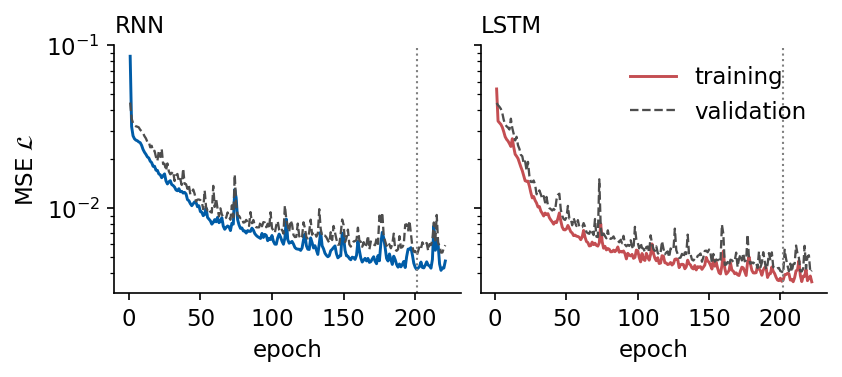

In [15]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), sharey=True, layout="constrained")
    for ax, kind in zip(axs, ("RNN", "LSTM")):
        h = hists[kind]
        ep = np.arange(1, h["epochs_run"] + 1)
        ax.semilogy(ep, h["train"], color=STYLE[kind]["color"], label="training")
        ax.semilogy(ep, h["val"], color="0.3", ls="--", lw=1.1, label="validation")
        ax.axvline(h["best_epoch"], color="0.5", ls=":", lw=1.0)
        ax.set_title(kind, loc="left"); ax.set_xlabel("epoch")
    axs[0].set_ylabel(r"MSE $\mathcal{L}$")
    axs[1].legend(loc="upper right")
    save(fig, "fig_lab039_training"); plt.show()

Both networks were stopped by early stopping, the RNN after 221 epochs with the best epoch 201 and the LSTM after 222 epochs with the best epoch 202. The training loss falls fast during the first 50 epochs and slowly afterwards, and the validation loss follows it at a slightly higher level with occasional spikes that last one or two epochs. Keeping the parameters of the best epoch makes the result insensitive to these spikes. The LSTM reaches the lower best validation loss, $3.99\times10^{-3}$ against $5.10\times10^{-3}$ for the RNN. Gradient clipping was never active, since the median gradient norm per epoch was 0.110 for the RNN and 0.088 for the LSTM, far below the threshold 1. One LSTM fit took 47 s on this processor and one RNN fit 13 s.

<hr/>
## 8. LSTM with flax nnx.LSTMCell

The same forecaster can be assembled from library parts. `nnx.LSTMCell` provides the cell and `nnx.RNN` runs it over the time axis of a batch of shape $(B,L,1)$ and returns the hidden states of shape $(B,L,n_h)$. A linear layer on the last of them gives the 50 leads. The library initialises the input matrices with LeCun normal entries, the recurrent matrices with an orthogonal matrix and all biases with zeros. To keep the comparison with our cell to the architecture and the code path, we set the forget bias to 1 after construction, as in our cell. Training uses the same function, the same optimiser, the same windows and the same seed.

In [16]:
class LibraryLSTM(nnx.Module):
    # flax nnx.LSTMCell run by nnx.RNN, linear readout of the last hidden state
    def __init__(self, n_h, n_out, *, rngs, forget_bias=1.0):
        cell = nnx.LSTMCell(1, n_h, rngs=rngs)
        cell.hf.bias[...] = jnp.full(n_h, forget_bias)          # forget bias, stored on the hidden-side matrix
        self.n_h = n_h
        self.rnn = nnx.RNN(cell)
        self.head = nnx.Linear(n_h, n_out, rngs=rngs)
    def __call__(self, V):
        # V: (B, L, 1) -> (B, n_out); the scan starts from c = h = 0
        zero = jnp.zeros((V.shape[0], self.n_h), V.dtype)
        return self.head(self.rnn(V, initial_carry=(zero, zero))[:, -1])

def train_library(name, seed=0):
    d_ = data[name]
    m, h = fit_network(LibraryLSTM(N_H, TAU_MAX, rngs=nnx.Rngs(seed)), d_[:4], seed=seed, verbose=False)
    Yt = np.asarray(d_[5], np.float64)
    return m, h, dict(pred=predict(m, d_[4]), time=h["time"], epochs=h["epochs_run"], best_epoch=h["best_epoch"],
                      best_val=h["best_val"], n_params=n_params(m), **score(predict(m, d_[4]), Yt))

nets["LSTM (flax)"], hists["LSTM (flax)"], R["LSTM (flax)"] = train_library("SantaFe")
h = hists["LSTM (flax)"]
print(f"flax LSTM forecaster: {n_params(nets['LSTM (flax)'])} parameters, {h['epochs_run']} epochs (best {h['best_epoch']}),"
      f" {h['time']:.1f} s, best validation loss {h['best_val']:.2e}, test C_tot = {R['LSTM (flax)']['Ctot']:.1f}"
      f" (our LSTM {R['LSTM']['Ctot']:.1f})")
nums["flax_lstm_santafe"] = dict(Ctot=float(R["LSTM (flax)"]["Ctot"]), best_val=float(h["best_val"]), time_s=float(h["time"]),
                                 epochs=int(h["epochs_run"]))

flax LSTM forecaster: 6002 parameters, 211 epochs (best 191), 54.8 s, best validation loss 3.81e-03, test C_tot = 45.0 (our LSTM 44.3)


The library forecaster has the same 6002 parameters as ours and was stopped after 211 epochs with the best epoch 191 and a best validation loss of $3.81\times10^{-3}$. Its test capacity, $C_{\rm tot}=45.0$, lies 0.7 above our LSTM with the same seed. The two cells compute the same equations, as the check above showed, and differ in the initialisation. The library draws its recurrent matrices from a modified orthogonal distribution and its input matrices from a LeCun normal distribution with fan-in 1, while our single matrix on $[\mathbf h_{k-1},s_k]$ is LeCun normal with fan-in $n_h+1=33$. A difference of 0.7 is comparable to the spread of 0.9 over three seeds of our LSTM measured in Section 13, so one run of each does not separate the two initialisations.

<hr/>
## 9. Forecast capacity on the Santa Fe laser

The capacity curves $C(\tau)=r(\tau)^2$ on the 951 test origins compare our LSTM and the flax LSTM with the simple RNN and the three baselines. The legend gives $C_{\rm tot}$ of each curve, and the grey line marks $C=0.5$, whose first crossing defines $\tau_{1/2}$.

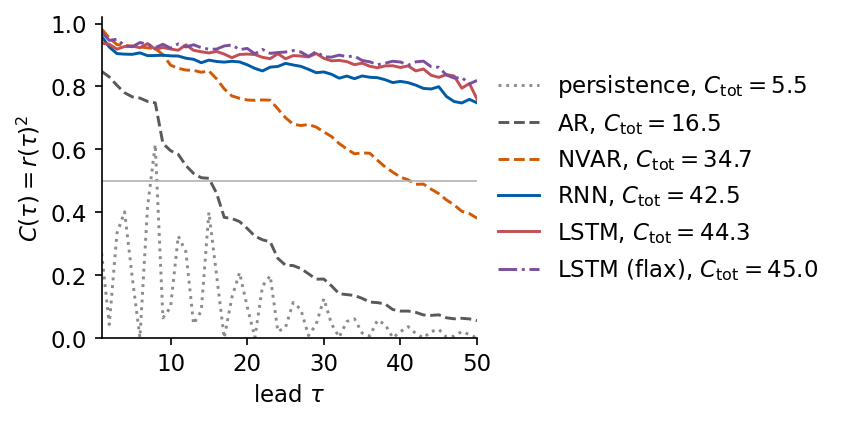

model         C_tot  tau_1/2    C(1)    C(2)    C(5)   C(10)   C(25)   C(50)
persistence     5.5        1   0.269   0.043   0.193   0.098   0.034   0.000
AR             16.5       16   0.848   0.830   0.767   0.596   0.232   0.056
NVAR           34.7       42   0.983   0.954   0.928   0.868   0.701   0.381
RNN            42.5      >50   0.959   0.925   0.902   0.897   0.873   0.748
LSTM           44.3      >50   0.937   0.934   0.928   0.919   0.888   0.759
LSTM (flax)    45.0      >50   0.973   0.946   0.926   0.922   0.909   0.819


In [17]:
CMP = ("persistence", "AR", "NVAR", "RNN", "LSTM", "LSTM (flax)")
STYLE["LSTM (flax)"] = dict(color="#7B4FA0", ls="-.")
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.7), layout="constrained")
    for m in CMP:
        ax.plot(TAUS, R[m]["C"], label=f"{m}, $C_{{\\rm tot}}={R[m]['Ctot']:.1f}$", **STYLE[m])
    ax.axhline(0.5, color="0.7", lw=0.8)
    ax.set_xlabel(r"lead $\tau$"); ax.set_ylabel(r"$C(\tau)=r(\tau)^2$"); ax.set_ylim(0, 1.02); ax.set_xlim(1, TAU_MAX)
    ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), handlelength=1.8)
    save(fig, "fig_lab039_capacity"); plt.show()
print(f"{'model':12s} {'C_tot':>6s} {'tau_1/2':>8s} " + " ".join(f"C({t})".rjust(7) for t in (1, 2, 5, 10, 25, 50)))
for m in CMP:
    print(f"{m:12s} {R[m]['Ctot']:6.1f} {str(R[m]['tau_half'] or '>50'):>8s} "
          + " ".join(f"{R[m]['C'][t - 1]:7.3f}" for t in (1, 2, 5, 10, 25, 50)))
nums["Ctot"] = {m: float(R[m]["Ctot"]) for m in CMP}
nums["tau_half"] = {m: R[m]["tau_half"] for m in CMP}
nums["C_tau"] = {m: {t: float(R[m]["C"][t - 1]) for t in (1, 2, 5, 10, 25, 50)} for m in CMP}

The networks keep $C(\tau)$ high over all 50 leads. The LSTM falls from $C(1)=0.937$ to $C(50)=0.759$, the flax LSTM from $0.973$ to $0.819$ and the RNN from $0.959$ to $0.748$, and none of the three crosses $C=0.5$, so $\tau_{1/2}>50$. NVAR is the best model at the first lead, with $C(1)=0.983$, and then decays to $0.381$ at $\tau=50$. The total capacities, 42.5 for the RNN, 44.3 for the LSTM and 45.0 for the flax LSTM, are therefore set at the long leads, where a fixed list of quadratic monomials of the last 32 values loses the phase of the pulsation and the learned state keeps it. The AR model has lost most of its skill after 25 leads, $C(25)=0.232$, and persistence oscillates with the pulsation period around a small value.

The capacity summarises each lead by one number. To see what it means we show the LSTM forecasts at the leads $\tau=1,2,5,10$. The upper panels show the target $s_{k+\tau}$ (black) and the forecast $\hat s_{k+\tau}$ (dashed) on 100 target steps around the collapse of the test block, each forecast made at the origin $k$, $\tau$ steps before its target. The lower panels show the forecast against the target on all 951 test origins, and the titles give $C(\tau)$. We also compare the squared error at $\tau=10$ of the 20 targets after the collapse with the rest of the test block.

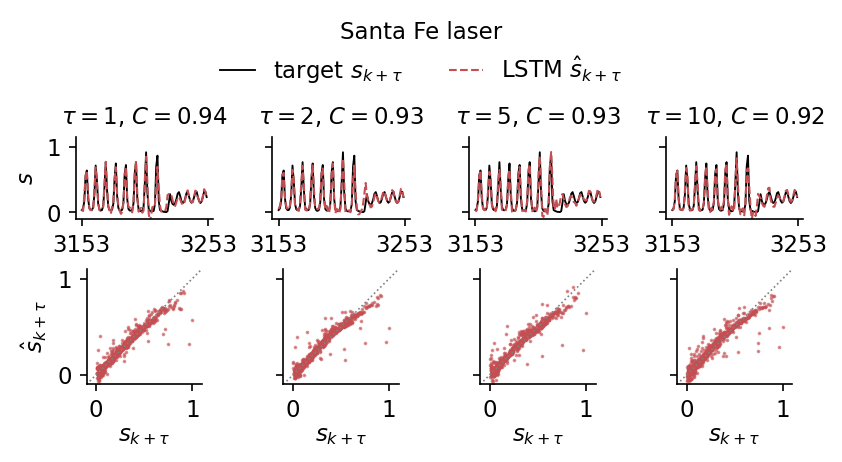

LSTM, tau = 10: 20 of 951 targets lie within 20 steps after a collapse (2.1%), and they carry 5.5% of the squared error; mean squared error there 0.0090, elsewhere 0.0034


In [18]:
TAU_SHOW = (1, 2, 5, 10)

def leads_figure(name, model, k_show, fname):
    # upper row: target and forecast on 100 target steps; lower row: forecast against target on all test origins
    P, Yt, s_ = res[name][model]["pred"], np.asarray(data[name][5], np.float64), sig[name]
    col = STYLE[model]["color"]
    with mpl.rc_context(SLIDE_RC):
        fig, axs = plt.subplots(2, 4, figsize=(5.5, 3.0), layout="constrained", gridspec_kw={"height_ratios": [1.0, 1.4]})
        for c_, t in enumerate(TAU_SHOW):
            a_t, a_s = axs[0, c_], axs[1, c_]
            i_show = k_show - t - K_TEST[0]             # the forecast of the target s_{k+tau} is made at the origin k
            a_t.plot(k_show, s_[k_show], color="k", lw=0.9, label=r"target $s_{k+\tau}$")
            a_t.plot(k_show, P[i_show, t - 1], "--", color=col, lw=1.0, label=model + r" $\hat s_{k+\tau}$")
            a_t.set_title(rf"$\tau={t}$, $C={res[name][model]['C'][t - 1]:.2f}$")
            a_t.set_ylim(-0.1, 1.15); a_t.set_yticks([0, 1]); a_t.set_xticks([k_show[0], k_show[-1] + 1])
            a_s.plot(Yt[:, t - 1], P[:, t - 1], ".", ms=1.5, color=col, alpha=0.6)
            a_s.plot([-0.1, 1.1], [-0.1, 1.1], color="0.5", lw=0.8, ls=":")
            a_s.set_xlim(-0.1, 1.1); a_s.set_ylim(-0.1, 1.1); a_s.set_aspect("equal")
            a_s.set_xticks([0, 1]); a_s.set_yticks([0, 1]); a_s.set_xlabel(r"$s_{k+\tau}$", labelpad=1)
            if c_ > 0:
                a_t.set_yticklabels([]); a_s.set_yticklabels([])
        axs[0, 0].set_ylabel("$s$"); axs[1, 0].set_ylabel(r"$\hat s_{k+\tau}$")
        fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=2, handlelength=1.5,
                   title=LABEL[name], title_fontsize=11)
        save(fig, fname); plt.show()

t0_show = collapse_test[0] - 60                     # 100 target steps around the collapse of the test block
leads_figure("SantaFe", "LSTM", np.arange(t0_show, t0_show + 100), "fig_lab039_leads")
P_lstm = R["LSTM"]["pred"]

# squared error at tau = 10 for targets within 20 steps after each collapse of the test block, against all targets
t_err = 10
err2 = (P_lstm[:, t_err - 1] - Y_test[:, t_err - 1]) ** 2
target_k = K_TEST + t_err
near = np.zeros(len(target_k), bool)
for c in collapse_test:
    near |= (target_k > c) & (target_k <= c + 20)
share = float(err2[near].sum() / err2.sum())
print(f"LSTM, tau = {t_err}: {near.sum()} of {len(near)} targets lie within 20 steps after a collapse"
      f" ({100 * near.mean():.1f}%), and they carry {100 * share:.1f}% of the squared error;"
      f" mean squared error there {err2[near].mean():.4f}, elsewhere {err2[~near].mean():.4f}")
nums["collapse_error"] = dict(tau=t_err, frac_targets=float(near.mean()), frac_err=share,
                              mse_near=float(err2[near].mean()), mse_else=float(err2[~near].mean()))

Before the collapse the forecasts follow the pulses at all four leads, and the scatter plots stay close to the diagonal with a spread that grows slowly from $C=0.94$ at $\tau=1$ to $C=0.92$ at $\tau=10$. The largest deviations appear at the collapse. Forecasts made a few steps before it continue the growing pulsation for one more pulse, and after it the network needs some steps to follow the small oscillation that starts the next cycle. The 20 targets after the collapse are 2.1% of the test targets and carry 5.5% of the squared error at $\tau=10$, with a mean squared error of 0.0090 against 0.0034 elsewhere. The collapse is the hardest part of the forecast, and with a single collapse in the test block its weight in $C_{\rm tot}$ is small.

<hr/>
## 10. Mackey–Glass signals

We now train the same three networks, the simple RNN, our LSTM and the flax LSTM, with seed 0 on the three Mackey–Glass signals, with the protocol and settings used for the laser. The baselines were fitted in Section 3.

In [19]:
for name in SIGNALS[1:]:
    for kind in ("RNN", "LSTM"):
        nets[(name, kind)], hists[(name, kind)], res[name][kind] = train_and_score(kind, name=name)
    nets[(name, "LSTM (flax)")], hists[(name, "LSTM (flax)")], res[name]["LSTM (flax)"] = train_library(name)
    print(f"{name:5s} " + " | ".join(f"{k} {res[name][k]['epochs']} epochs, {res[name][k]['time']:.0f} s"
                                     for k in ("RNN", "LSTM", "LSTM (flax)")))
print()
print(f"{'model':12s}" + "".join(f"{n:>10s}" for n in SIGNALS) + "     (C_tot, maximum 50)")
for m in CMP:
    print(f"{m:12s}" + "".join(f"{res[n][m]['Ctot']:10.1f}" for n in SIGNALS))
print(f"\n{'model':12s}" + "".join(f"{n:>10s}" for n in SIGNALS) + "     (tau_1/2, '>50' if C stays above 0.5)")
for m in CMP:
    print(f"{m:12s}" + "".join(f"{str(res[n][m]['tau_half'] or '>50'):>10s}" for n in SIGNALS))
print(f"\n{'model':12s}" + "".join(f"{n:>10s}" for n in SIGNALS) + "     (C at tau = 50)")
for m in CMP:
    print(f"{m:12s}" + "".join(f"{res[n][m]['C'][-1]:10.3f}" for n in SIGNALS))
nums["Ctot_all"] = {n: {m: float(res[n][m]["Ctot"]) for m in CMP} for n in SIGNALS}
nums["tau_half_all"] = {n: {m: res[n][m]["tau_half"] for m in CMP} for n in SIGNALS}
nums["C_tau_all"] = {n: {m: {t: float(res[n][m]["C"][t - 1]) for t in (1, 2, 5, 10, 25, 50)} for m in CMP} for n in SIGNALS}

MG15  RNN 250 epochs, 16 s | LSTM 210 epochs, 43 s | LSTM (flax) 250 epochs, 61 s


MG25  RNN 164 epochs, 11 s | LSTM 250 epochs, 56 s | LSTM (flax) 250 epochs, 63 s


MG35  RNN 239 epochs, 16 s | LSTM 250 epochs, 56 s | LSTM (flax) 250 epochs, 65 s

model          SantaFe      MG15      MG25      MG35     (C_tot, maximum 50)
persistence        5.5      19.5      13.3      11.8
AR                16.5      49.8      33.1      38.0
NVAR              34.7      50.0      45.5      48.6
RNN               42.5      50.0      49.4      49.7
LSTM              44.3      50.0      49.9      49.9
LSTM (flax)       45.0      50.0      49.9      49.9

model          SantaFe      MG15      MG25      MG35     (tau_1/2, '>50' if C stays above 0.5)
persistence          1         6         8        10
AR                  16       >50        42       >50
NVAR                42       >50       >50       >50
RNN                >50       >50       >50       >50
LSTM               >50       >50       >50       >50
LSTM (flax)        >50       >50       >50       >50

model          SantaFe      MG15      MG25      MG35     (C at tau = 50)
persistence      0.000     0.368  

On the limit cycle all three networks reach $C_{\rm tot}=50.0$, as NVAR does. A periodic signal is a smooth function of its own past, and no model above the linear one gains anything there. In the chaotic regimes the networks separate from NVAR at long leads. At $\tau_{\rm MG}=25$ the RNN reaches 49.4 and both LSTMs 49.9, against 45.5 for NVAR, and at $\tau_{\rm MG}=35$ the RNN reaches 49.7 and both LSTMs 49.9, against 48.6. The capacity at the last lead is close to one for every network, $C(50)=0.980$ (RNN), 0.994 (LSTM) and 0.997 (flax LSTM) at $\tau_{\rm MG}=25$, and 0.980, 0.997 and 0.995 at $\tau_{\rm MG}=35$. Every network keeps $C(\tau)>0.5$ over all 50 leads on all three signals. These networks were trained with one seed, and their differences of a few tenths of a unit of $C_{\rm tot}$ on Mackey–Glass are smaller than the seed spread measured on the laser, so the Mackey–Glass results do not rank the three networks. Several of these runs used all 250 epochs, so a longer training could still lower their validation loss.

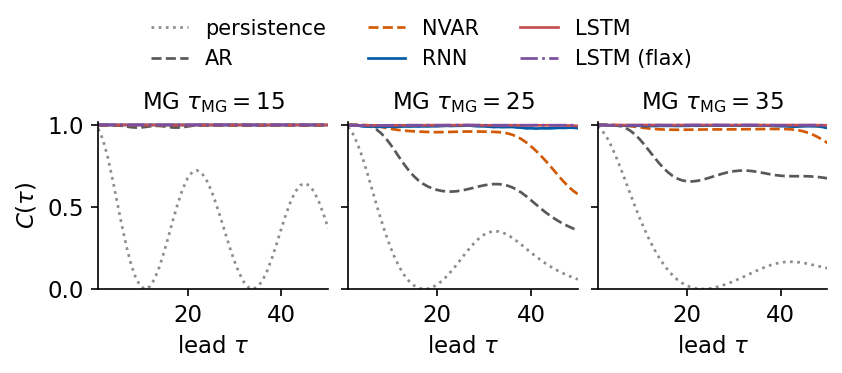

In [20]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.4), sharey=True, layout="constrained")
    for ax, name in zip(axs, SIGNALS[1:]):
        for m in CMP:
            ax.plot(TAUS, res[name][m]["C"], lw=1.3, label=m, **STYLE[m])
        ax.set_title(LABEL[name]); ax.set_xlabel(r"lead $\tau$"); ax.set_xlim(1, TAU_MAX); ax.set_ylim(0, 1.02)
    axs[0].set_ylabel(r"$C(\tau)$")
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside upper center", ncol=3, fontsize=10, handlelength=1.8)
    save(fig, "fig_lab039_capacity_mg"); plt.show()

The capacity curves of the three networks lie on top of each other near $C=1$ for all signals, and the differences between models come from the linear and quadratic baselines, which lose capacity in the chaotic regimes. The forecasts of the LSTM at the leads $\tau=1,2,5,10$ follow below, one figure per signal, with the target and the forecast on the first 100 test steps from sample 3010 on and the scatter of forecast against target on all test origins.

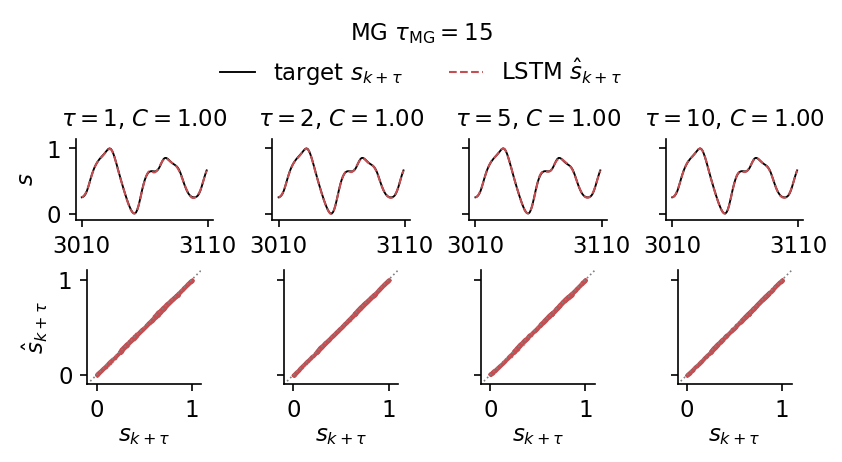

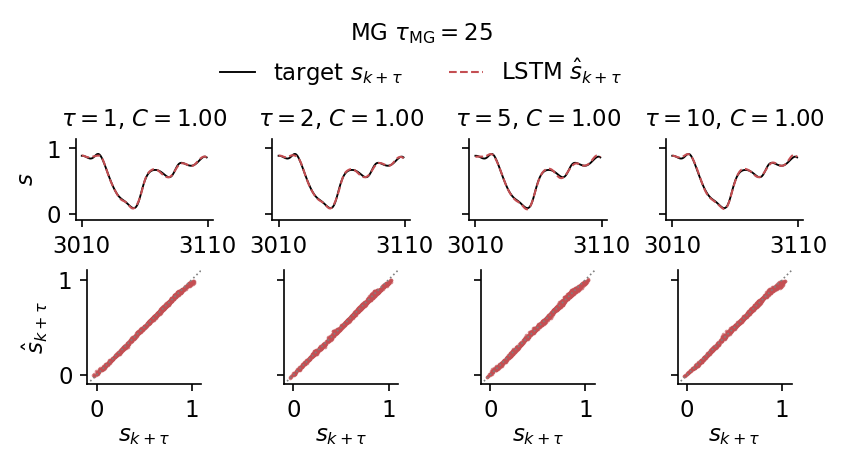

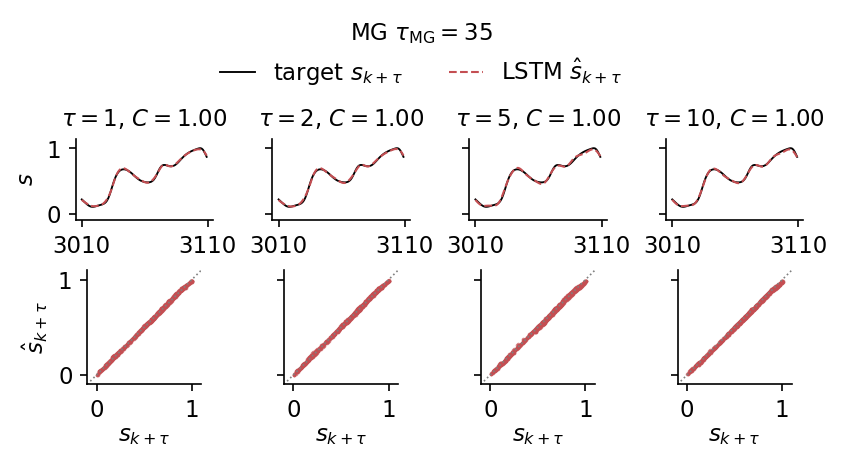

In [21]:
for name in SIGNALS[1:]:
    leads_figure(name, "LSTM", np.arange(N_TRAIN + 10, N_TRAIN + 110), f"fig_lab039_leads_{name.lower()}")

At all four leads the LSTM forecasts of the three Mackey–Glass signals are indistinguishable from the targets in the traces, and the scatter plots collapse onto the diagonal with $C\ge0.99$. The smooth oscillations of the delay equation, sampled once per time unit, change little within ten steps, and a window of 64 values contains what the next ten values require. The laser, whose pulses change within a few samples and whose collapses depend on a slowly growing amplitude, remains the demanding test.

We collect the LSTM forecasts at the three leads $\tau=1$, 5 and 10 on all four signals in one figure. Each row belongs to one signal and each column to one lead, and every panel shows the first 100 test targets $s_{k+\tau}$ together with the forecast $\hat s_{k+\tau}$ made $\tau$ steps earlier. The title of each panel gives the capacity $C(\tau)$ computed on the whole test block.

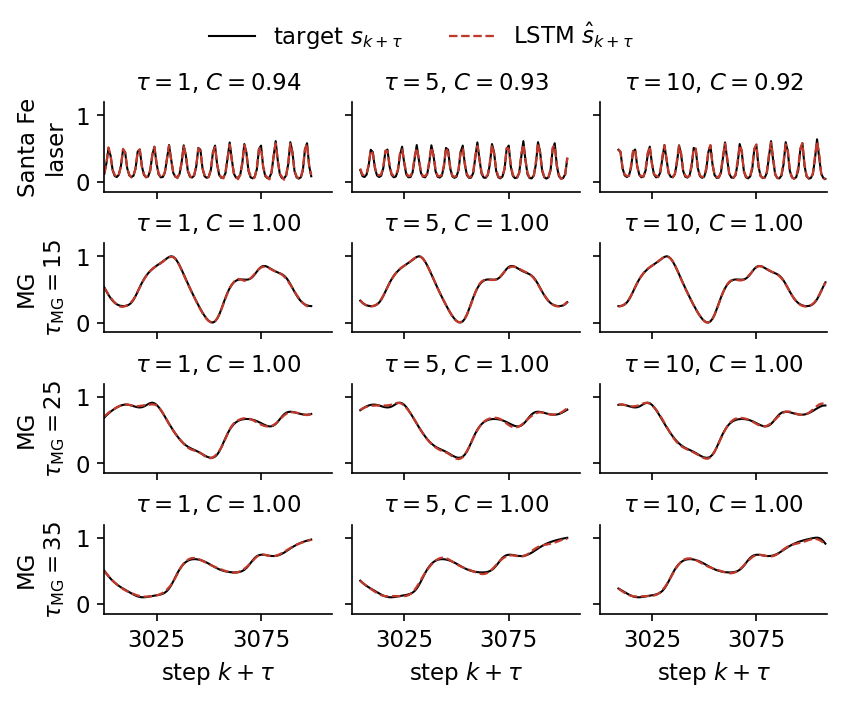

LSTM C(tau) on the whole test block
signal      C(1)    C(5)   C(10)
SantaFe    0.937   0.928   0.919
MG15       0.999   1.000   1.000
MG25       0.998   0.997   0.997
MG35       0.999   0.998   0.999


In [22]:
TAU_GRID, N_SHOW = (1, 5, 10), 100
COL_LSTM = "#C0392B"                                # model colour shared by the four forecaster notebooks
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(4, 3, figsize=(5.5, 4.6), layout="constrained")
    for r_, name in enumerate(SIGNALS):
        P, Yt = res[name]["LSTM"]["pred"], np.asarray(data[name][5], np.float64)
        for c_, t in enumerate(TAU_GRID):
            ax = axs[r_, c_]
            kk = K_TEST[:N_SHOW] + t                    # target steps of the first 100 test origins
            ax.plot(kk, Yt[:N_SHOW, t - 1], color="k", lw=1.0, label=r"target $s_{k+\tau}$")
            ax.plot(kk, P[:N_SHOW, t - 1], "--", color=COL_LSTM, lw=1.1, label=r"LSTM $\hat s_{k+\tau}$")
            ax.set_title(fr"$\tau={t}$, $C={res[name]['LSTM']['C'][t - 1]:.2f}$")
            ax.set_ylim(-0.15, 1.2); ax.set_yticks([0, 1])
            ax.set_xlim(N_TRAIN, N_TRAIN + 109); ax.set_xticks([3025, 3075])
            if c_ > 0:
                ax.set_yticklabels([])
            if r_ < len(SIGNALS) - 1:
                ax.set_xticklabels([])
            else:
                ax.set_xlabel(r"step $k+\tau$")
        axs[r_, 0].set_ylabel(LABEL[name].replace("Fe ", "Fe\n").replace("MG $", "MG\n$"))     # signal label on two lines to fit the row height
    fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=2)
    save(fig, "fig_lab039_leads_all"); plt.show()
print(f"LSTM C(tau) on the whole test block\n{'signal':8s}" + "".join(f"C({t})".rjust(8) for t in TAU_GRID))
for name in SIGNALS:
    print(f"{name:8s}" + "".join(f"{res[name]['LSTM']['C'][t - 1]:8.3f}" for t in TAU_GRID))

<hr/>
## 11. Gradients through time

We now measure how strongly the forecast depends on an input $m$ steps before the forecast origin. For a window $\mathbf v_k$ and the output vector $\hat{\mathbf y}_k\in\mathbb R^{50}$ we define the sensitivity
$$G(m)=\Big\langle\Big\|\frac{\partial\hat{\mathbf y}_k}{\partial s_{k-m}}\Big\|_2\Big\rangle_k,\qquad m=0,\dots,L-1,$$
the Euclidean norm over the 50 outputs averaged over 200 test windows. The derivative of the loss with respect to $s_{k-m}$, and the contribution of step $k-m$ to the gradient of the input weights, both contain this Jacobian, so $G(m)$ shows how much training signal reaches $m$ steps back. We compute the full Jacobian with `jax.jacrev` for the untrained networks (seed 0) and for the trained ones. For the LSTM we also show the product along the cell state,
$$F(m)=\Big\langle\prod_{i=k-m+1}^{k}f_{i,j}\Big\rangle_{k,j},$$
averaged over the units $j$ and the windows, the size of the direct-path factor $\prod\mathrm{diag}(\mathbf f_i)$ of Section 5.

In [23]:
@nnx.jit
def input_sensitivity(model, V):
    # G(m) = < || d y_hat / d s_{k-m} ||_2 >, m = 0..L-1 (m = 0 is the last input s_k)
    J = jax.vmap(jax.jacrev(lambda v: model(v[None])[0]))(V)       # (B, n_out, L, 1)
    return jnp.sqrt((J[..., 0] ** 2).sum(1)).mean(0)[::-1]

def lstm_forget_values(model, V):
    # forget-gate values f_k of all units along the windows V: (L, B, n_h)
    cell = model.cell
    def step(carry, s):
        i, f, g, o = cell.gates(carry, s)
        c = f * carry[0] + i * g
        return (c, o * jnp.tanh(c)), f
    return jax.lax.scan(step, cell.init_carry(V.shape[0], V.dtype), jnp.swapaxes(V, 0, 1))[1]

def cell_path_product(model, V):
    # F(m) = < prod_{i=k-m+1}^{k} f_{i,j} > over units j and windows, m = 0..L-1 (F(0) = 1)
    f = lstm_forget_values(model, V)[::-1]                          # last step first
    return np.concatenate([[1.0], np.asarray(jnp.cumprod(f, axis=0).mean(axis=(1, 2)))[:-1]])

V_g = data_sf[4][:200]
G = {(kind, "untrained"): np.asarray(input_sensitivity(make_model(kind, 0), V_g)) for kind in ("RNN", "LSTM")}
G.update({(kind, "trained"): np.asarray(input_sensitivity(nets[kind], V_g)) for kind in ("RNN", "LSTM")})
F_path = {"untrained": cell_path_product(make_model("LSTM", 0), V_g), "trained": cell_path_product(nets["LSTM"], V_g)}
mm = np.arange(L_WIN)
nums["sensitivity"] = {}
for (kind, state), g in G.items():
    rate = np.polyfit(mm[10:], np.log10(g[10:]), 1)[0]            # decades per step for m = 10..63
    nums["sensitivity"][f"{kind} {state}"] = dict(G0=float(g[0]), G10=float(g[10]), G30=float(g[30]),
                                                  G63=float(g[63]), rate=float(rate))
    print(f"{kind:4s} {state:9s}: log10 G(m) at m = 0, 10, 30, 63: "
          + " ".join(f"{np.log10(g[j]):6.2f}" for j in (0, 10, 30, 63)) + f" | slope for m >= 10: {rate:+.3f} decades per step")
for state, F_ in F_path.items():
    print(f"LSTM {state:9s}: F(m) at m = 1, 5, 10, 30: " + " ".join(f"{F_[j]:.2e}" for j in (1, 5, 10, 30)))
nums["cell_path"] = {st: {m_: float(F_[m_]) for m_ in (1, 5, 10, 30)} for st, F_ in F_path.items()}

RNN  untrained: log10 G(m) at m = 0, 10, 30, 63:   0.85   0.08  -1.31  -3.26 | slope for m >= 10: -0.061 decades per step
LSTM untrained: log10 G(m) at m = 0, 10, 30, 63:  -0.54  -0.83  -1.12  -1.92 | slope for m >= 10: -0.020 decades per step
RNN  trained  : log10 G(m) at m = 0, 10, 30, 63:   0.29   0.62   0.20  -0.73 | slope for m >= 10: -0.023 decades per step
LSTM trained  : log10 G(m) at m = 0, 10, 30, 63:   0.19   0.69  -0.00  -1.07 | slope for m >= 10: -0.035 decades per step
LSTM untrained: F(m) at m = 1, 5, 10, 30: 7.34e-01 2.14e-01 4.64e-02 1.13e-04
LSTM trained  : F(m) at m = 1, 5, 10, 30: 6.46e-01 1.39e-01 2.52e-02 8.60e-05


The figure shows $G(m)$ for the two networks before and after training on the laser, and $F(m)$ of the LSTM.

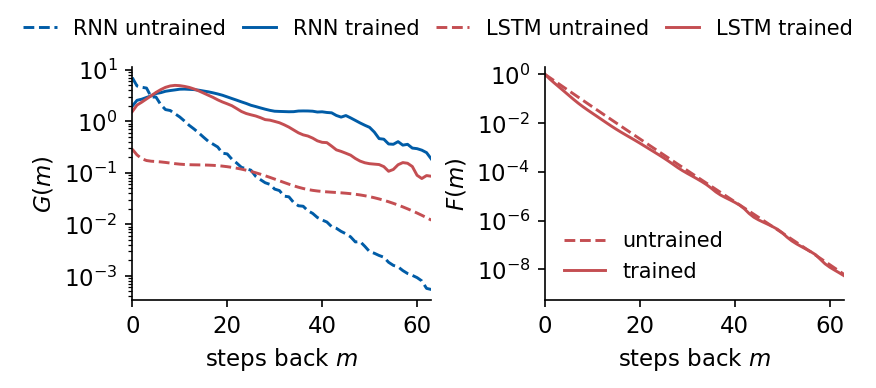

In [24]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.5), layout="constrained")
    ax = axs[0]
    for kind in ("RNN", "LSTM"):
        for state, ls in (("untrained", "--"), ("trained", "-")):
            ax.semilogy(mm, G[(kind, state)], color=STYLE[kind]["color"], ls=ls, label=f"{kind} {state}")
    ax.set_xlabel("steps back $m$"); ax.set_ylabel(r"$G(m)$"); ax.set_xlim(0, L_WIN - 1)
    ax = axs[1]
    for state, ls in (("untrained", "--"), ("trained", "-")):
        ax.semilogy(mm, np.maximum(F_path[state], 1e-30), color=STYLE["LSTM"]["color"], ls=ls, label=state)
    ax.set_xlabel("steps back $m$"); ax.set_ylabel(r"$F(m)$"); ax.set_xlim(0, L_WIN - 1)
    ax.set_ylim(max(1e-30, F_path["trained"][-1] / 10), 2); ax.legend(loc="lower left", fontsize=10)
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside upper center", ncol=4, fontsize=10, handlelength=1.6,
               columnspacing=0.8)
    save(fig, "fig_lab039_gradients"); plt.show()

Before training the sensitivity of the RNN falls from $10^{0.85}$ at $m=0$ to $10^{-3.26}$ at $m=63$, at a rate of 0.061 decades per step for $m\ge10$, while that of the LSTM falls from $10^{-0.54}$ to $10^{-1.92}$, at 0.020 decades per step. The untrained LSTM thus passes the influence of distant inputs three times more slowly per step. After training both curves rise above their initial values over most of the window and peak around $m\approx10$, more than one pulse back. The trained RNN keeps the slower decay, 0.023 decades per step against 0.035 for the trained LSTM, and at $m=63$ it is more sensitive than the LSTM. On the laser the training has made the LSTM depend less on the far end of the window than the RNN.

The direct cell path cannot explain the slow decay of $G(m)$ alone. Its size $F(m)$ falls to $2.5\times10^{-2}$ after 10 steps and to $8.6\times10^{-5}$ after 30 steps in the trained network, much faster than $G(m)$. The influence of distant inputs therefore travels mainly through the other terms of the full Jacobian, through the hidden state and the gates. The direct path becomes the dominant carrier only when the forget values approach 1, which the next two sections examine.

<hr/>
## 12. Forget gates and memory times

The forget values of the trained LSTM show which memory times the network uses on the laser. We collect $f_{k,j}$ for all units $j$, all 64 steps and all test windows, and for every unit we convert the mean $\bar f_j$ to the memory time $\tau_{{\rm mem},j}=-1/\ln\bar f_j$. The untrained network is shown for comparison.

trained:   mean f = 0.636, fraction of f > 0.9: 0.014, fraction of f < 0.1: 0.001
untrained: mean f = 0.734, fraction of f > 0.9: 0.000
memory times of the trained LSTM: median 2.5, min 1.1, max 3.5 steps (untrained median 3.3, max 3.6)
MG15  LSTM memory times: median 3.3, max 7.7 steps


MG25  LSTM memory times: median 3.4, max 6.3 steps
MG35  LSTM memory times: median 3.5, max 6.8 steps


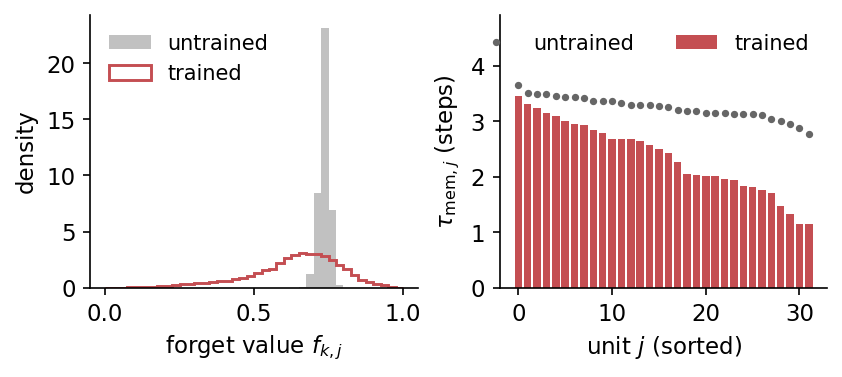

In [25]:
f_tr = np.asarray(lstm_forget_values(nets["LSTM"], data_sf[4]))          # (L, n_test, n_h)
f_un = np.asarray(lstm_forget_values(make_model("LSTM", 0), data_sf[4]))
tau_mem = -1 / np.log(f_tr.mean(axis=(0, 1)))                              # one memory time per unit
tau_mem_un = -1 / np.log(f_un.mean(axis=(0, 1)))
print(f"trained:   mean f = {f_tr.mean():.3f}, fraction of f > 0.9: {np.mean(f_tr > 0.9):.3f},"
      f" fraction of f < 0.1: {np.mean(f_tr < 0.1):.3f}")
print(f"untrained: mean f = {f_un.mean():.3f}, fraction of f > 0.9: {np.mean(f_un > 0.9):.3f}")
print(f"memory times of the trained LSTM: median {np.median(tau_mem):.1f}, min {tau_mem.min():.1f},"
      f" max {tau_mem.max():.1f} steps (untrained median {np.median(tau_mem_un):.1f}, max {tau_mem_un.max():.1f})")
nums["tau_mem_mg"] = {}
for name in SIGNALS[1:]:
    t_mg = -1 / np.log(np.asarray(lstm_forget_values(nets[(name, "LSTM")], data[name][4])).mean(axis=(0, 1)))
    nums["tau_mem_mg"][name] = dict(median=float(np.median(t_mg)), max=float(t_mg.max()))
    print(f"{name:5s} LSTM memory times: median {np.median(t_mg):.1f}, max {t_mg.max():.1f} steps")
nums["forget"] = dict(f_mean=float(f_tr.mean()), frac_above_0p9=float(np.mean(f_tr > 0.9)), frac_below_0p1=float(np.mean(f_tr < 0.1)),
                      f_mean_untrained=float(f_un.mean()), tau_median=float(np.median(tau_mem)), tau_min=float(tau_mem.min()),
                      tau_max=float(tau_mem.max()), tau_median_untrained=float(np.median(tau_mem_un)),
                      tau_max_untrained=float(tau_mem_un.max()))

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained")
    ax = axs[0]
    bins = np.linspace(0, 1, 41)
    ax.hist(f_un.ravel(), bins=bins, density=True, color="0.6", alpha=0.6, label="untrained")
    ax.hist(f_tr.ravel(), bins=bins, density=True, histtype="step", color=STYLE["LSTM"]["color"], lw=1.4, label="trained")
    ax.set_xlabel(r"forget value $f_{k,j}$"); ax.set_ylabel("density"); ax.legend(loc="upper left", fontsize=10)
    ax = axs[1]
    order = np.argsort(tau_mem)[::-1]
    ax.bar(np.arange(N_H), tau_mem[order], color=STYLE["LSTM"]["color"], width=0.8, label="trained")
    ax.plot(np.arange(N_H), np.sort(tau_mem_un)[::-1], "o", ms=2.5, color="0.4", label="untrained")
    ax.set_xlabel("unit $j$ (sorted)"); ax.set_ylabel(r"$\tau_{{\rm mem},j}$ (steps)")
    ax.set_ylim(0, 1.35 * max(tau_mem.max(), tau_mem_un.max())); ax.legend(loc="upper right", fontsize=10, ncol=2)
    save(fig, "fig_lab039_forget"); plt.show()

Before training the forget values form a narrow peak around 0.73, the value $\sigma(1)$ set by the forget bias, with a mean of 0.734 and no value above 0.9. Training spreads them over the whole interval $(0,1)$ with a maximum near 0.7 and lowers the mean to 0.636. Only 1.4% of all values exceed 0.9 and 0.1% lie below 0.1. The memory times of the 32 units range from 1.1 to 3.5 steps with a median of 2.5 steps, below the initial median of 3.3 steps. The LSTMs trained on the Mackey–Glass signals behave in the same way, with median memory times of 3.3, 3.4 and 3.5 steps and largest values of 7.7, 6.3 and 6.8 steps at $\tau_{\rm MG}=15$, 25 and 35.

On all four signals the network has thus learned to forget fast, within less than half a pulsation period of the laser. The forecast is computed from the last few values and from the hidden state, and the long-memory path that the cell offers stays unused. The forget gate acts as a learnable time constant, and these data set it short.

<hr/>
## 13. Hidden size and random seeds

The hidden size $n_h$ sets the capacity of the model. We train the LSTM with $n_h=4,8,16,32,64$ (seed 0) and record the best validation loss and the test $C_{\rm tot}$. The result of a network also depends on the random initial weights and on the order of the minibatches, both fixed by the seed, so for $n_h=32$ we repeat the training of the LSTM and of the RNN with the seeds 1 and 2.

In [26]:
sweep = {}
for nh_ in (4, 8, 16, 32, 64):
    if nh_ == N_H:
        r_ = R["LSTM"]
    else:
        r_ = train_and_score("LSTM", 0, n_h=nh_)[2]
    sweep[nh_] = dict(params=r_["n_params"], val=r_["best_val"], Ctot=r_["Ctot"], time=r_["time"], epochs=r_["epochs"])
    print(f"LSTM n_h = {nh_:2d}: {r_['n_params']:6d} parameters, best validation loss {r_['best_val']:.2e},"
          f" test C_tot = {r_['Ctot']:.1f}, {r_['epochs']} epochs, {r_['time']:.0f} s")
nums["hidden_sweep"] = {str(k): v for k, v in sweep.items()}

seed_ctot = {k: [R[k]["Ctot"]] for k in ("RNN", "LSTM")}
seed_C = {k: [R[k]["C"]] for k in ("RNN", "LSTM")}
for kind in ("RNN", "LSTM"):
    for seed in (1, 2):
        r_ = train_and_score(kind, seed)[2]
        seed_ctot[kind].append(r_["Ctot"]); seed_C[kind].append(r_["C"])
    v = np.array(seed_ctot[kind])
    print(f"{kind:5s} C_tot for seeds 0, 1, 2: " + ", ".join(f"{x:.1f}" for x in v)
          + f"  (mean {v.mean():.1f}, range {v.max() - v.min():.1f})")
nums["seeds_Ctot"] = {k: [float(x) for x in v] for k, v in seed_ctot.items()}

LSTM n_h =  4:    346 parameters, best validation loss 1.85e-02, test C_tot = 28.2, 250 epochs, 10 s


LSTM n_h =  8:    770 parameters, best validation loss 1.16e-02, test C_tot = 36.0, 250 epochs, 13 s


LSTM n_h = 16:   2002 parameters, best validation loss 6.61e-03, test C_tot = 41.7, 192 epochs, 19 s
LSTM n_h = 32:   6002 parameters, best validation loss 3.99e-03, test C_tot = 44.3, 222 epochs, 47 s


LSTM n_h = 64:  20146 parameters, best validation loss 2.69e-03, test C_tot = 45.6, 228 epochs, 113 s


RNN   C_tot for seeds 0, 1, 2: 42.5, 41.6, 42.2  (mean 42.1, range 0.9)


LSTM  C_tot for seeds 0, 1, 2: 44.3, 44.0, 44.9  (mean 44.4, range 0.9)


The left panel shows the test $C_{\rm tot}$ against the hidden size together with the three seeds of the RNN and the LSTM at $n_h=32$ and the NVAR value, and the right panel the capacity curves of the two networks at $n_h=32$, the mean over the three seeds as a line and the range between the lowest and the highest seed as a band.

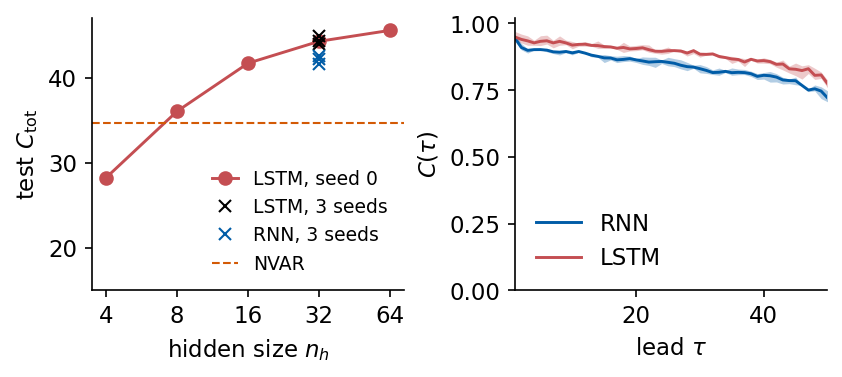

In [27]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained")
    ax = axs[0]
    nhs = np.array(list(sweep))
    ax.plot(nhs, [sweep[n]["Ctot"] for n in nhs], "o-", color=STYLE["LSTM"]["color"], label="LSTM, seed 0")
    ax.plot([N_H] * 3, seed_ctot["LSTM"], "x", color="k", ms=6, label="LSTM, 3 seeds")
    ax.plot([N_H] * 3, seed_ctot["RNN"], "x", color=STYLE["RNN"]["color"], ms=6, label="RNN, 3 seeds")
    for m in ("NVAR",):
        ax.axhline(R[m]["Ctot"], **STYLE[m], lw=1.0, label=m)
    ax.set_xscale("log", base=2); ax.set_xticks(nhs, [str(n) for n in nhs])
    ax.set_xlabel("hidden size $n_h$"); ax.set_ylabel(r"test $C_{\rm tot}$")
    ax.set_ylim(15, 47); ax.legend(loc="lower right", fontsize=9, handlelength=1.4)
    ax = axs[1]
    for kind in ("RNN", "LSTM"):
        Cs = np.array(seed_C[kind])
        ax.fill_between(TAUS, Cs.min(0), Cs.max(0), color=STYLE[kind]["color"], alpha=0.3, lw=0)
        ax.plot(TAUS, Cs.mean(0), color=STYLE[kind]["color"], label=kind)
    ax.set_xlabel(r"lead $\tau$"); ax.set_ylabel(r"$C(\tau)$"); ax.set_xlim(1, TAU_MAX); ax.set_ylim(0, 1.02)
    ax.legend(loc="lower left")
    save(fig, "fig_lab039_size_seeds"); plt.show()

The capacity grows with the hidden size, from $C_{\rm tot}=28.2$ with 4 units and 346 parameters to 36.0 with 8, 41.7 with 16, 44.3 with 32 and 45.6 with 64 units and 20146 parameters, and the best validation loss decreases in the same order, from $1.85\times10^{-2}$ to $2.69\times10^{-3}$. Eight units are enough to pass NVAR with its 560 features. The gain per doubling shrinks from 7.8 between 4 and 8 units to 1.3 between 32 and 64 units, while the training time of the largest network, 113 s, is 2.4 times that of $n_h=32$. The networks with 4 and 8 units used all 250 epochs.

Over three seeds the LSTM gives $C_{\rm tot}=44.3$, 44.0 and 44.9, with mean 44.4, and the RNN 42.5, 41.6 and 42.2, with mean 42.1. The seed ranges are 0.9 for both and do not overlap, so for the laser, these sizes and this training protocol the LSTM is ahead of the RNN by about two units of $C_{\rm tot}$ independently of the seed. The bands of the capacity curves show where the difference arises, at all leads beyond the first few, with the largest gap at the long leads. Since the trained LSTM uses short memory times, its advantage on the laser is consistent with the multiplicative gating of the recent inputs, which the simple RNN with its single tanh layer per step lacks. We did not test this interpretation separately.

<hr/>
## 14. Gradients over long windows

The laser does not force the networks to remember far into the past, so the trained networks above never had to use long memory. The property that the gates provide is visible before any training. We take windows of $T=200$ values drawn independently and uniformly from $[0,1]$ and compute the sensitivity $G(m)$ of untrained networks with one output for $m=0,\dots,199$, averaged over 100 windows and over five random initialisations. For the LSTM we vary the initial forget bias, $b_f=0$, $1$ and $3$, which gives forget values near $\sigma(0)=0.5$, $\sigma(1)\approx0.73$ and $\sigma(3)\approx0.95$ for a small input, memory times $\tau_{\rm mem}=-1/\ln f$ of about 1.4, 3.2 and 20 steps.

RNN          log10 G(199)/G(0) =  -22.37 (range -26.16 .. -18.40), slope -0.1120 decades per step for m >= 20


LSTM, b_f=0  log10 G(199)/G(0) =  -29.55 (range -32.14 .. -27.17), slope -0.1476 decades per step for m >= 20
LSTM, b_f=1  log10 G(199)/G(0) =   -6.34 (range -8.23 .. -4.14), slope -0.0297 decades per step for m >= 20


LSTM, b_f=3  log10 G(199)/G(0) =    0.07 (range -2.23 .. 1.35), slope +0.0043 decades per step for m >= 20


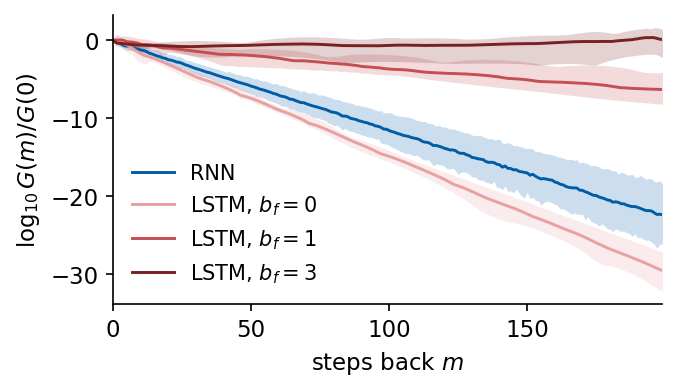

In [28]:
T_LONG, N_INIT = 200, 5
V_long = jnp.asarray(np.random.default_rng(7).uniform(0, 1, (100, T_LONG, 1)), jnp.float32)
def long_model(kind, seed, fb):
    rngs = nnx.Rngs(seed)
    cell = RNNCell(1, N_H, rngs=rngs) if kind == "RNN" else LSTMCell(1, N_H, rngs=rngs, forget_bias=fb)
    return Recurrent(cell, N_H, 1, rngs=rngs)
G_long = {}
for lab, kind, fb in (("RNN", "RNN", None), ("LSTM, $b_f=0$", "LSTM", 0.0), ("LSTM, $b_f=1$", "LSTM", 1.0),
                      ("LSTM, $b_f=3$", "LSTM", 3.0)):
    logs = np.array([np.log10(np.asarray(input_sensitivity(long_model(kind, sd, fb), V_long))) for sd in range(N_INIT)])
    G_long[lab] = logs
    ratio = logs[:, -1] - logs[:, 0]
    rate = np.polyfit(np.arange(20, T_LONG), logs.mean(0)[20:], 1)[0]
    print(f"{lab.replace('$', ''):12s} log10 G(199)/G(0) = {ratio.mean():7.2f} (range {ratio.min():.2f} .. {ratio.max():.2f}),"
          f" slope {rate:+.4f} decades per step for m >= 20")
nums["long_window"] = {lab.replace("$", "").replace("\\", ""): dict(log10_ratio=float((L_[:, -1] - L_[:, 0]).mean()),
                       rate=float(np.polyfit(np.arange(20, T_LONG), L_.mean(0)[20:], 1)[0])) for lab, L_ in G_long.items()}

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.5), layout="constrained")
    cols = {"RNN": STYLE["RNN"]["color"], "LSTM, $b_f=0$": "#E8A0A0", "LSTM, $b_f=1$": STYLE["LSTM"]["color"],
            "LSTM, $b_f=3$": "#7A1F22"}
    mm_l = np.arange(T_LONG)
    for lab, L_ in G_long.items():
        rel = L_ - L_[:, :1]
        ax.fill_between(mm_l, rel.min(0), rel.max(0), color=cols[lab], alpha=0.2, lw=0)
        ax.plot(mm_l, rel.mean(0), color=cols[lab], label=lab)
    ax.set_xlabel("steps back $m$"); ax.set_ylabel(r"$\log_{10}G(m)/G(0)$"); ax.set_xlim(0, T_LONG - 1)
    ax.legend(loc="lower left", fontsize=10)
    save(fig, "fig_lab039_long_gradients"); plt.show()

After 200 steps the sensitivity of the untrained RNN has fallen by a factor of $10^{-22.4}$ on average, at a rate of 0.112 decades per step, and the five initialisations lie between $10^{-26.2}$ and $10^{-18.4}$. An input this far back sends no usable gradient to the weights. The LSTM with $b_f=0$ is even worse, $10^{-29.6}$, since its forget values near $1/2$ halve the cell content at every step. With $b_f=1$ the loss is $10^{-6.3}$ on average, and with $b_f=3$ the sensitivity at $m=199$ is as large as at $m=0$, on average $10^{0.07}$ with a range from $10^{-2.2}$ to $10^{1.4}$, and its slope is $+0.004$ decades per step.

The forget bias thus turns the vanishing gradient of the recurrent network into a gradient that reaches 200 steps back. This is the mechanism proposed by Hochreiter and Schmidhuber and made learnable by Gers *et al.*, and it is why a positive forget bias is the standard initialisation. Whether the training then uses this long memory depends on the task. On the laser and on Mackey–Glass, where the window of 64 values contains the information that the forecast needs, the trained networks set short memory times, as Section 12 showed. These measurements are made at initialisation, and we did not train networks on a task that requires memory over hundreds of steps.

<hr/>
## Summary

We built a direct multi-horizon forecaster from an LSTM cell, which reads a window of $L=64$ past values from a zero state and returns the leads $\tau=1,\dots,50$ through a linear readout of its last hidden state, and scored it by the capacity $C(\tau)=r(\tau)^2$ and its sum $C_{\rm tot}$. The LSTM implementation in JAX, a single matrix on the concatenation $[\mathbf h_{k-1},s_k]$ inside a `jax.lax.scan`, gives the same hidden states as the flax cells `nnx.LSTMCell` and `nnx.OptimizedLSTMCell` in float32, and the same forecaster built from `nnx.LSTMCell` and `nnx.RNN` reaches $C_{\rm tot}=45.0$ on the laser, 0.7 above ours with the same seed and comparable to our seed spread of 0.9.

On the Santa Fe laser the recurrent networks beat the linear and quadratic baselines. The LSTM reaches $C_{\rm tot}=44.4$ on average over three seeds, against 42.1 for the RNN, 34.7 for NVAR and 16.5 for AR, and with seed 0 it keeps $C(\tau)>0.5$ at all 50 leads. Its largest errors occur at the collapse of the pulsation, of which the test block contains one. The capacity grows with the hidden size up to the largest size tested, 64 units. On the Mackey–Glass limit cycle all models down to linear AR are close to the maximum, and in the two chaotic regimes all three networks reach between 49.4 and 49.9, with differences below the seed spread.

The gradient analysis separates what the LSTM offers from what it uses. Along the cell state the derivative is the diagonal matrix of forget values, and with a positive forget bias the sensitivity of an untrained network to an input 200 steps back stays of order one, where the RNN loses 22 decades. Trained on the laser, the forget gates choose memory times of only a few steps, and the trained LSTM depends less on the far end of the window than the trained RNN. Its advantage on these signals therefore comes from the gated processing of the recent past, at these window and network sizes and with this training protocol, and the long memory that the forget gate makes possible would matter for signals whose forecast requires information from far outside such a window.

## References

- U. Hübner, N. B. Abraham, C. O. Weiss, *Dimensions and entropies of chaotic intensity pulsations in a single-mode far-infrared NH$_3$ laser*, Phys. Rev. A **40**, 6354 (1989), [doi:10.1103/PhysRevA.40.6354](https://doi.org/10.1103/PhysRevA.40.6354)
- M. C. Mackey, L. Glass, *Oscillation and chaos in physiological control systems*, Science **197**, 287 (1977), [doi:10.1126/science.267326](https://doi.org/10.1126/science.267326)
- J. L. Elman, *Finding structure in time*, Cogn. Sci. **14**, 179 (1990), [doi:10.1207/s15516709cog1402_1](https://doi.org/10.1207/s15516709cog1402_1)
- Y. Bengio, P. Simard, P. Frasconi, *Learning long-term dependencies with gradient descent is difficult*, IEEE Trans. Neural Netw. **5**, 157 (1994), [doi:10.1109/72.279181](https://doi.org/10.1109/72.279181)
- S. Hochreiter, J. Schmidhuber, *Long short-term memory*, Neural Comput. **9**, 1735 (1997), [doi:10.1162/neco.1997.](https://doi.org/10.1162/neco.1997.)
- F. A. Gers, J. Schmidhuber, F. Cummins, *Learning to forget: continual prediction with LSTM*, Neural Comput. **12**, 2451 (2000), [doi:10.1162/089976600300015015](https://doi.org/10.1162/089976600300015015)
- R. Pascanu, T. Mikolov, Y. Bengio, *On the difficulty of training recurrent neural networks*, ICML (2013), [arXiv:1211.5063](https://arxiv.org/abs/1211.5063)
- D. P. Kingma, J. Ba, *Adam: a method for stochastic optimization*, ICLR (2015), [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)
- D. J. Gauthier, E. Bollt, A. Griffith, W. A. S. Barbosa, *Next generation reservoir computing*, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)

In [29]:
nums["runtime_s"] = round(time.time() - t_start, 1)
def to_py(o):
    if isinstance(o, dict): return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
with open(f"{OUT}/numbers_lab039.json", "w") as fh:
    json.dump(to_py(nums), fh, indent=1)

# LaTeX macros \labthreenine... (letters only) for the numbers the slides use
TAG = {"persistence": "Persistence", "AR": "AR", "NVAR": "NVAR", "RNN": "RNN", "LSTM": "LSTM"}
WORD = {1: "One", 2: "Two", 4: "Four", 5: "Five", 8: "Eight", 10: "Ten", 16: "Sixteen", 25: "TwentyFive",
        32: "ThirtyTwo", 50: "Fifty", 64: "SixtyFour"}
macros = {}
for m in CMP[:-1]:
    macros[f"Ctot{TAG[m]}"] = f"{R[m]['Ctot']:.1f}"
    macros[f"TauHalf{TAG[m]}"] = str(R[m]["tau_half"]) if R[m]["tau_half"] else "{>}50"
    for t in (1, 2, 5, 10):
        macros[f"C{TAG[m]}{WORD[t]}"] = f"{R[m]['C'][t - 1]:.2f}"
for k in ("AR", "NVAR"):
    macros[f"Order{k}"] = str(R[k]["p"])
for k in ("RNN", "LSTM"):
    macros[f"Params{k}"] = str(nums["param_counts"][k])
    v = np.array(seed_ctot[k])
    macros[f"SeedMin{k}"] = f"{v.min():.1f}"; macros[f"SeedMax{k}"] = f"{v.max():.1f}"; macros[f"SeedMean{k}"] = f"{v.mean():.1f}"
    macros[f"FitTime{k}"] = f"{nums['training'][k]['time_s']:.0f}"
    macros[f"Epochs{k}"] = str(nums["training"][k]["epochs"])
    macros[f"BestVal{k}"] = f"{nums['training'][k]['best_val']:.2e}"
    for st in ("untrained", "trained"):
        d = nums["sensitivity"][f"{k} {st}"]
        macros[f"GRate{k}{st.capitalize()}"] = f"{d['rate']:+.3f}"
        macros[f"GRatio{k}{st.capitalize()}"] = f"{d['G63'] / d['G0']:.1e}"
for nh_, d in sweep.items():
    macros[f"CtotHidden{WORD[nh_]}"] = f"{d['Ctot']:.1f}"
macros["Period"] = f"{nums['santafe']['period']:.1f}"
macros["FMean"] = f"{nums['forget']['f_mean']:.2f}"
macros["FMeanUntrained"] = f"{nums['forget']['f_mean_untrained']:.2f}"
macros["TauMemMedian"] = f"{nums['forget']['tau_median']:.1f}"
macros["TauMemMax"] = f"{nums['forget']['tau_max']:.1f}"
macros["TauMemMedianUntrained"] = f"{nums['forget']['tau_median_untrained']:.1f}"
macros["CollapseErrShare"] = f"{100 * nums['collapse_error']['frac_err']:.0f}"
macros["CollapseTargetShare"] = f"{100 * nums['collapse_error']['frac_targets']:.0f}"
SIGTAG = {"SantaFe": "SantaFe", "MG15": "MGfifteen", "MG25": "MGtwentyfive", "MG35": "MGthirtyfive"}
TAG["LSTM (flax)"] = "FlaxLSTM"
for n in SIGNALS:
    for m in CMP:
        macros[f"Ctot{TAG[m]}{SIGTAG[n]}"] = f"{res[n][m]['Ctot']:.1f}"
        th = res[n][m]["tau_half"]
        macros[f"TauHalf{TAG[m]}{SIGTAG[n]}"] = str(th) if th else "{>}50"
for lab, d in nums["long_window"].items():
    tag = {"RNN": "RNN", "LSTM, b_f=0": "LSTMbZero", "LSTM, b_f=1": "LSTMbOne", "LSTM, b_f=3": "LSTMbThree"}[lab]
    macros[f"LongLogRatio{tag}"] = f"{d['log10_ratio']:.1f}"
    macros[f"LongDecades{tag}"] = f"{abs(d['log10_ratio']):.0f}"
for n in SIGNALS[1:]:
    macros[f"TauMemMedian{SIGTAG[n]}"] = f"{nums['tau_mem_mg'][n]['median']:.1f}"
assert all(k.isalpha() for k in macros)
with open(f"{OUT}/nb_numbers_lab039.tex", "w") as fh:
    for k, v in macros.items():
        fh.write(f"\\newcommand{{\\labthreenine{k}}}{{{v}}}\n")
print(f"{len(macros)} macros written; total runtime {nums['runtime_s'] / 60:.1f} min")

126 macros written; total runtime 14.3 min
